# PAPILA Glaucoma Screening — 12-Model Pretrained Benchmark (patient-level 5-fold CV)

## 1. Objective and experimental limitations

**Objective.** Rapidly and reproducibly compare 12 ImageNet-pretrained image classifiers on the PAPILA fundus dataset for a **binary screening task**:
`Diagnosis = 0 → Healthy (0)`, `Diagnosis ∈ {1, 2} → Positive (1)`.

**Priority order used throughout:** data integrity and labels → patient-level leakage prevention → valid evaluation → reproducibility → runtime → visual presentation.

**How the notebook is protected against silent errors**
- Nothing is initialised or trained until the **data audit (Sections 3-7) reports `PASS`**. Any integrity issue is fatal and the offending rows are displayed — nothing is silently dropped, repaired or duplicated.
- The label mapping is applied only after the diagnosis codes have been checked (see Section 5 — a gate that needs documentary evidence or your explicit confirmation).
- `OD` images are matched only to `patient_data_od.xlsx`, `OS` images only to `patient_data_os.xlsx`.

**Limitations (please read before interpreting results)**
1. Results are **5-fold patient-level cross-validation estimates on a small dataset**; there is no untouched external test set. They are **not clinically validated** and must not be presented as such.
2. All models use the **same standardised 299×299 input and identical hyper-parameters** for 5 epochs. That is a fair *screening* setting, **not** each architecture's optimal native resolution or tuned configuration; rankings may change with tuning, longer training, or other resolutions.
3. The positive class merges the two non-zero diagnosis codes. If code 2 denotes *glaucoma suspects* (to be confirmed in Section 5), the positive class mixes confirmed and suspected cases.
4. **Reported metrics are those of the final (5th) epoch.** Selecting an epoch/checkpoint by held-out-fold AUROC would leak validation information into the estimate (Section 4 forbids that), so the "best-validation-AUROC" checkpoint requested in Section 9 is saved only as a *diagnostic* artifact and is never used for the reported numbers.
5. Documented, explicit model-specific exceptions: **DeiT-Tiny is not in torchvision** → loaded from `timm` (pretrained, ImageNet-1k); **ViT-B/16** position embeddings are bicubically interpolated from 14×14 to 18×18 (299 // 16 = 18; the remaining 11 right/bottom pixels are ignored by the stride-16 patch embedding); **Inception-v3's auxiliary classifier is disabled**.
6. Both eyes of a patient are different images but correlated; they are always kept in the same fold.

**How to run:** attach the PAPILA dataset, enable the GPU (T4) and — for the first run — **Internet** (needed only to download ImageNet weights; torchvision weights and the timm DeiT weights are cached afterwards). Then *Run All*. To resume after an interruption see Section 17.

## 2. Environment and GPU verification

Versions and hardware are **verified at run time** rather than assumed. A mismatch with the expected versions is reported as a warning (APIs used here are stable across recent torch/torchvision releases).

In [1]:
import os, sys, platform, random, json, time, re, gc, hashlib, shutil, warnings, traceback, io
from pathlib import Path
from datetime import datetime, timezone
from collections import OrderedDict

# Needed for deterministic cuBLAS; must be set before CUDA is initialised.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tqdm.auto import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, confusion_matrix

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

EXPECTED_ENV = {"torch": "2.11.0", "torchvision": "0.26.0"}
print(f"Python       : {sys.version.split()[0]} ({platform.platform()})")
print(f"torch        : {torch.__version__}  (expected {EXPECTED_ENV['torch']})")
print(f"torchvision  : {torchvision.__version__}  (expected {EXPECTED_ENV['torchvision']})")
print(f"scikit-learn : {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
for lib in ("torch", "torchvision"):
    actual = globals()[lib].__version__.split("+")[0]
    if actual != EXPECTED_ENV[lib]:
        warnings.warn(f"{lib} {actual} differs from the expected {EXPECTED_ENV[lib]}; continuing because the APIs used are stable, but note it in your report.")

try:
    import timm
    print(f"timm         : {timm.__version__} (used only for DeiT-Tiny, which torchvision does not provide)")
except Exception as e:  # recoverable: only the DeiT-Tiny model will be marked 'not run'
    timm = None
    print(f"timm         : NOT available ({e!r}) -> DeiT-Tiny will be marked as not run")

assert hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler") and hasattr(torch.amp, "autocast"), "torch.amp API missing"

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    print(f"GPU          : {props.name} | {props.total_memory/1024**3:.1f} GiB | compute capability {props.major}.{props.minor} | CUDA {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()}")
    if "T4" not in props.name:
        print(f"NOTE: expected a Tesla T4 but found '{props.name}'. Timing numbers are specific to the hardware actually used.")
else:
    DEVICE = torch.device("cpu")
    warnings.warn("CUDA is not available: falling back to CPU. The full benchmark will be extremely slow; use the GPU accelerator.")
AMP_ENABLED = DEVICE.type == "cuda"
print(f"Device       : {DEVICE} | mixed precision (torch.amp): {AMP_ENABLED}")

INPUT_ROOT = Path("/kaggle/input")
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./kaggle_working")
WORK.mkdir(parents=True, exist_ok=True)
du = shutil.disk_usage(WORK)
print(f"Output dir   : {WORK.resolve()} | free disk {du.free/1024**3:.1f} GiB")

Python       : 3.13.15 (Linux-6.18.55+-x86_64-with-glibc2.39)
torch        : 2.11.0+cu128  (expected 2.11.0)
torchvision  : 0.26.0+cu128  (expected 0.26.0)
scikit-learn : 1.6.1 | pandas 2.3.3 | numpy 2.1.3
timm         : 1.0.29 (used only for DeiT-Tiny, which torchvision does not provide)
GPU          : Tesla T4 | 14.6 GiB | compute capability 7.5 | CUDA 12.8 | cuDNN 91900
Device       : cuda | mixed precision (torch.amp): True
Output dir   : /kaggle/working | free disk 19.5 GiB


## 3. Dataset discovery and path validation

`/kaggle/input` is searched for `patient_data_od.xlsx`. **Exactly one** hit is accepted; zero or several hits stop the notebook (the candidate paths are printed) instead of silently picking one. The matching dataset directory must contain `FundusImages/`, `patient_data_od.xlsx` and `patient_data_os.xlsx`.

In [2]:
class AuditFailure(RuntimeError):
    """Fatal data-integrity problem: the notebook must not proceed to splitting/training."""

EXPECTED_N_IMAGES = 488          # confirmed observation, verified (not assumed) below
PARSE_LOG = []                   # every parsing decision + reason (written to the audit report)
def log_decision(msg):
    PARSE_LOG.append(msg); print("  •", msg)

hits = []
for dirpath, _dirs, files in os.walk(INPUT_ROOT):
    for f in files:
        if f.lower() == "patient_data_od.xlsx":
            hits.append(Path(dirpath) / f)
hits = sorted(hits)
if len(hits) == 0:
    raise AuditFailure(f"No 'patient_data_od.xlsx' found under {INPUT_ROOT}. Is the PAPILA dataset attached to this notebook?")
if len(hits) > 1:
    print("Multiple candidate datasets found:"); [print("  ", h) for h in hits]
    raise AuditFailure("Ambiguous dataset: more than one 'patient_data_od.xlsx' under /kaggle/input. Remove the extra dataset or hard-code the intended path.")

od_path = hits[0]
clin_dir = od_path.parent
DATASET_ROOT = clin_dir.parent if clin_dir.name.lower() == "clinicaldata" else clin_dir
OS_XLSX = next((p for p in clin_dir.iterdir() if p.name.lower() == "patient_data_os.xlsx"), None)
FUNDUS_DIR = next((p for p in DATASET_ROOT.iterdir() if p.is_dir() and p.name.lower() == "fundusimages"), None)
OD_XLSX = od_path
missing = [n for n, v in (("patient_data_os.xlsx", OS_XLSX), ("FundusImages/", FUNDUS_DIR)) if v is None]
if missing:
    raise AuditFailure(f"Dataset at {DATASET_ROOT} is missing: {missing}")

print("Dataset root :", DATASET_ROOT)
print("FundusImages :", FUNDUS_DIR)
print("OD workbook  :", OD_XLSX)
print("OS workbook  :", OS_XLSX)
print("Files in FundusImages (all regular files, recursive):", sum(1 for p in FUNDUS_DIR.rglob("*") if p.is_file()))

Dataset root : /kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20275b5b6a0d99dc9dfe3007e9f
FundusImages : /kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20275b5b6a0d99dc9dfe3007e9f/FundusImages
OD workbook  : /kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20275b5b6a0d99dc9dfe3007e9f/ClinicalData/patient_data_od.xlsx
OS workbook  : /kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20275b5b6a0d99dc9dfe3007e9f/ClinicalData/patient_data_os.xlsx
Files in FundusImages (all regular files, recursive): 488


## 4. Raw Excel inspection

Both workbooks are loaded with `header=None, dtype=object` so that **no value is coerced or interpreted** yet. The first rows are shown so the header structure can be judged from the actual content.

In [3]:
RAW = {}
for lat, path in (("OD", OD_XLSX), ("OS", OS_XLSX)):
    sheets = pd.ExcelFile(path).sheet_names
    if len(sheets) != 1:
        raise AuditFailure(f"{path.name} has {len(sheets)} sheets {sheets}; ambiguous - inspect manually.")
    RAW[lat] = pd.read_excel(path, header=None, dtype=object)
    print(f"\n=== {path.name} | sheet '{sheets[0]}' | shape {RAW[lat].shape} (observed earlier: 247 x 13) ===")
    display(RAW[lat].head(6))


=== patient_data_od.xlsx | sheet 'Sheet1' | shape (247, 13) (observed earlier: 247 x 13) ===


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,NaN,Age,Gender,Diagnosis,Refractive_Defect,NaN,NaN,Phakic/Pseudophakic,IOP,NaN,Pachymetry,Axial_Length,VF_MD
1,NaN,Age,Gender,Diagnosis,dioptre_1,dioptre_2,astigmatism,Phakic/Pseudophakic,Pneumatic,Perkins,Pachymetry,Axial_Length,VF_MD
2,ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,#002,47,0,2,0.75,-1.75,90,0,21,NaN,586,23.64,-0.07
4,#004,58,1,1,1.5,-1.75,85,0,NaN,19,501,23.06,-3.26
5,#005,89,1,1,-0.75,-1.25,101,1,13,14,565,23.81,-14.98



=== patient_data_os.xlsx | sheet 'Sheet1' | shape (247, 13) (observed earlier: 247 x 13) ===


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,NaN,Age,Gender,Diagnosis,Refractive_Defect,NaN,NaN,Phakic/Pseudophakic,IOP,NaN,Pachymetry,Axial_Length,VF_MD
1,NaN,Age,Gender,Diagnosis,dioptre_1,dioptre_2,astigmatism,Phakic/Pseudophakic,Pneumatic,Perkins,Pachymetry,Axial_Length,VF_MD
2,ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,#002,47,0,2,-0.5,-1.5,88,0,20,NaN,603,23.77,0.17
4,#004,58,1,1,1.5,-2.5,85,1,NaN,19,511,22.96,-6.77
5,#005,89,1,1,-0.5,-2,100,1,24,10,575,24.33,-7.44


## 5. Clinical header detection and label-code audit

**Header detection** (content-based, no hard-coded positions): the `ID` cell is searched for in the first 10 rows; the `Diagnosis` cell is searched in the rows up to and including the `ID` row. Each must be found **exactly once**, otherwise the raw rows are displayed and the notebook stops. Records start on the row after the `ID` row. Fully blank rows are reported, never silently used as records; rows with a missing/invalid ID or diagnosis are kept and flagged.

**One ID normalisation function** is used for both image IDs and clinical IDs (`RET002` and `#002` both → patient number `2`); its behaviour is asserted before use.

**Label-code gate.** The meaning of the diagnosis codes must not be assumed. The notebook (a) lists every distinct raw value, (b) searches the dataset folder and the workbooks for documentation, and (c) applies the requested mapping only if the codes are within `{0,1,2}`, both a zero group and a non-zero group exist, **and** the meaning is either found in the dataset's own documentation or confirmed by you via `USER_CONFIRMS_LABEL_CODES`.

In [4]:
# ---- Set to True ONLY after you have confirmed the meaning of the diagnosis codes
# (read the evidence printed below and the PAPILA dataset paper: Kovalyk et al., Scientific Data 2022).
USER_CONFIRMS_LABEL_CODES = True
ALLOWED_CODES = {0, 1, 2}

def norm_text(x):
    return "" if pd.isna(x) else re.sub(r"\s+", " ", str(x)).strip().lower()

_ID_RE = re.compile(r"^(?:RET)?#?0*(\d+)$", re.IGNORECASE)
def normalize_patient_id(x):
    """THE single ID-normalisation rule (used for images AND clinical records).
    Strips whitespace, an optional 'RET' prefix and/or '#', and leading zeros; returns the patient number
    as int, or None if the value is missing / not of that form. Floats are accepted only if integer-valued."""
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return None
    if isinstance(x, (bool, np.bool_)):
        return None
    if isinstance(x, (int, np.integer)):
        s = str(int(x))
    elif isinstance(x, (float, np.floating)):
        if not float(x).is_integer():
            return None
        s = str(int(x))
    else:
        s = re.sub(r"\s+", "", str(x))
    m = _ID_RE.match(s)
    return int(m.group(1)) if m else None

# explicit verification of the rule BEFORE it is applied to data
assert normalize_patient_id("RET002") == normalize_patient_id("#002") == normalize_patient_id(" #002 ") == normalize_patient_id(2.0) == 2
assert normalize_patient_id("ret010") == 10 and normalize_patient_id("abc") is None and normalize_patient_id(float("nan")) is None
print("ID normalisation rule verified: 'RET002' == '#002' == 2.0 -> patient number 2")

def parse_diagnosis(x):
    """Returns (int_code | None, status) - never coerces silently. Handles 0, 0.0, '0', ' 1 ', NaN, text."""
    if x is None or (not isinstance(x, str) and pd.isna(x)) or (isinstance(x, str) and x.strip() == ""):
        return None, "missing"
    try:
        v = float(str(x).strip())
    except ValueError:
        return None, "non_numeric"
    if not np.isfinite(v) or not float(v).is_integer():
        return None, "non_integer"
    return int(v), "ok"

assert parse_diagnosis(0.0) == (0, "ok") and parse_diagnosis("0") == (0, "ok") and parse_diagnosis(" 2 ") == (2, "ok")
assert parse_diagnosis(np.nan)[1] == "missing" and parse_diagnosis("x")[1] == "non_numeric" and parse_diagnosis(1.5)[1] == "non_integer"

def detect_layout(raw, lat, max_scan_rows=10):
    scan = raw.iloc[:max_scan_rows]
    id_cells = [(r, c) for r in range(len(scan)) for c in range(scan.shape[1])
                if re.fullmatch(r"(patient\s*)?id", norm_text(scan.iat[r, c]))]
    if len(id_cells) != 1:
        display(scan)
        raise AuditFailure(f"[{lat}] expected exactly one 'ID' header cell in the first {max_scan_rows} rows, found {id_cells}.")
    hdr_row, id_col = id_cells[0]
    
    diag_cells = [(r, c) for r in range(hdr_row + 1) for c in range(raw.shape[1])
                  if re.match(r"^diagnos[ie]s\b", norm_text(raw.iat[r, c]))]
    
    # FIX: Group detected header cells by column index to handle multi-row header cells in Excel
    diag_cols = sorted(list(set(c for r, c in diag_cells)))
    if len(diag_cols) != 1:
        display(raw.iloc[:hdr_row + 2])
        raise AuditFailure(f"[{lat}] expected exactly one 'Diagnosis' header column at/above the ID row, found columns {diag_cols} from cells {diag_cells}.")
    
    diag_col = diag_cols[0]
    diag_row = max(r for r, c in diag_cells if c == diag_col)
    
    first = raw.iat[hdr_row + 1, id_col] if hdr_row + 1 < len(raw) else None
    if normalize_patient_id(first) is None:
        display(raw.iloc[:hdr_row + 4])
        raise AuditFailure(f"[{lat}] first row after the header has an unparseable ID {first!r}; structure is ambiguous.")
    labels = {c: " | ".join(str(raw.iat[r, c]).strip() for r in range(hdr_row + 1) if not pd.isna(raw.iat[r, c])) for c in range(raw.shape[1])}
    return dict(hdr_row=hdr_row, id_col=id_col, diag_row=diag_row, diag_col=diag_col, first_data_row=hdr_row + 1, labels=labels)

LAYOUT = {}
for lat in ("OD", "OS"):
    print(f"\n[{lat}] header detection")
    L = detect_layout(RAW[lat], lat)
    LAYOUT[lat] = L
    log_decision(f"{lat}: 'ID' header found at raw row {L['hdr_row']}, column {L['id_col']} (unique match in first rows) -> records start at raw row {L['first_data_row']}.")
    log_decision(f"{lat}: 'Diagnosis' header found at raw row {L['diag_row']}, column {L['diag_col']} (label text: {L['labels'][L['diag_col']]!r}).")
    obs = (L["hdr_row"] == 2 and L["id_col"] == 0 and RAW[lat].shape == (247, 13))
    log_decision(f"{lat}: layout {'matches' if obs else 'DIFFERS from'} the earlier observation (ID row 2, col 0, shape 247x13); detection above is content-based either way.")
    print("    column labels:", L["labels"])

def extract_records(raw, lat, L):
    rows, blank = [], []
    for i in range(L["first_data_row"], len(raw)):
        row = raw.iloc[i]
        if row.isna().all():
            blank.append(i); continue
        rid, dg = row.iloc[L["id_col"]], row.iloc[L["diag_col"]]
        nid = normalize_patient_id(rid)
        d, dstat = parse_diagnosis(dg)
        id_status = "missing" if (not isinstance(rid, str) and pd.isna(rid)) or (isinstance(rid, str) and rid.strip() == "") else ("ok" if nid is not None else "invalid_format")
        rows.append(dict(laterality=lat, excel_row=i + 1, original_clinical_id=None if pd.isna(rid) else str(rid),
                         norm_id=nid, id_status=id_status, diag_raw=None if pd.isna(dg) else dg, diag=d, diag_status=dstat))
    df = pd.DataFrame(rows)
    df["diag"] = pd.array(df["diag"], dtype="Int64")
    df["norm_id"] = pd.array(df["norm_id"], dtype="Int64")
    return df, blank

CLIN, BLANK_ROWS = {}, {}
for lat in ("OD", "OS"):
    CLIN[lat], BLANK_ROWS[lat] = extract_records(RAW[lat], lat, LAYOUT[lat])
    log_decision(f"{lat}: {len(CLIN[lat])} clinical records extracted; {len(BLANK_ROWS[lat])} fully blank rows reported (raw rows {BLANK_ROWS[lat][:10]}) and not treated as records.")
CLIN_ALL = pd.concat([CLIN["OD"], CLIN["OS"]], ignore_index=True)
print("\nObserved raw clinical ID examples:", CLIN_ALL["original_clinical_id"].dropna().head(5).tolist())

# ---------------- label-code audit ----------------
print("\nRaw diagnosis values (python type -> count) per eye file:")
for lat in ("OD", "OS"):
    vals = CLIN[lat]["diag_raw"].map(lambda v: (type(v).__name__, v))
    print(f"  {lat}:", {k: int(v) for k, v in vals.value_counts(dropna=False).items()})
codes_seen = sorted(set(int(c) for c in CLIN_ALL["diag"].dropna().unique()))
print("Distinct parsed diagnosis codes:", codes_seen)
print("Parsed distribution (rows):\n", pd.crosstab(CLIN_ALL["laterality"], CLIN_ALL["diag"].astype("object").fillna("NaN")))

# documentation search: (1) dataset folder files, (2) text cells inside the workbooks
HINT = re.compile(r"diagnos|healthy|glaucom|suspect|normal|control", re.IGNORECASE)
doc_files = [p for p in DATASET_ROOT.rglob("*") if p.is_file() and p.suffix.lower() not in {".jpg", ".jpeg", ".png"} and p.suffix.lower() != ".xlsx"]
print("\nPotential documentation files in the dataset folder:", [str(p.relative_to(DATASET_ROOT)) for p in doc_files] or "none")
EVIDENCE = []
for p in doc_files:
    if p.suffix.lower() in {".txt", ".md", ".csv", ".json", ".rtf", ".html"}:
        try:
            for ln in p.read_text(errors="ignore").splitlines():
                if HINT.search(ln): EVIDENCE.append(f"{p.name}: {ln.strip()[:200]}")
        except Exception as e:
            print("  could not read", p, e)
    else:
        print(f"  NOTE: {p.name} is not parsed automatically - inspect it manually for the code definitions.")
for lat in ("OD", "OS"):
    for r in range(RAW[lat].shape[0]):
        for c in range(RAW[lat].shape[1]):
            v = RAW[lat].iat[r, c]
            if isinstance(v, str) and HINT.search(v) and not re.fullmatch(r"(?i)\s*(patient\s*)?id\s*", v) and r <= LAYOUT[lat]["hdr_row"] + 0:
                EVIDENCE.append(f"{lat} workbook header cell (row {r}, col {c}): {v.strip()[:200]}")
print("\nDocumentation evidence found inside the dataset files:")
[print("  -", e) for e in (EVIDENCE or ["(none)"])]

ev_text = " ".join(EVIDENCE).lower()
doc_zero_healthy = bool(re.search(r"\b0\b\W{0,12}(?:healthy|normal|control|non-?glaucoma)", ev_text))
doc_nonzero_pos = bool(re.search(r"\b[12]\b\W{0,12}(?:glaucoma|suspect)", ev_text))
DOC_CONFIRMED = doc_zero_healthy and doc_nonzero_pos

unsupported_codes = [c for c in codes_seen if c not in ALLOWED_CODES]
has_zero, has_nonzero = (0 in codes_seen), any(c != 0 for c in codes_seen)
LABEL_GATE = OrderedDict(
    codes_within_allowed_set=not unsupported_codes,
    zero_and_nonzero_groups_present=has_zero and has_nonzero,
    meaning_documented_in_dataset_files=DOC_CONFIRMED,
    meaning_confirmed_by_user_flag=USER_CONFIRMS_LABEL_CODES,
)
LABEL_GATE_PASSED = (LABEL_GATE["codes_within_allowed_set"] and LABEL_GATE["zero_and_nonzero_groups_present"]
                     and (DOC_CONFIRMED or USER_CONFIRMS_LABEL_CODES))
print("\nLabel-code gate:", dict(LABEL_GATE), "->", "PASSED" if LABEL_GATE_PASSED else "NOT PASSED")
if not LABEL_GATE_PASSED:
    print("\n>>> The meaning of the diagnosis codes could not be established from the dataset files.\n"
          "    Binary labels will NOT be created and training will NOT start. Confirm the code definitions\n"
          "    (published PAPILA description, to be verified by you: 0 = healthy, 1 = glaucoma, 2 = glaucoma suspect),\n"
          "    then set USER_CONFIRMS_LABEL_CODES = True at the top of this cell and re-run from here.")
else:
    log_decision("Label mapping 0 -> Healthy(0); {1,2} -> Positive(1) validated: codes within {0,1,2}, both groups present, meaning " +
                 ("documented in dataset files." if DOC_CONFIRMED else "confirmed by the user flag USER_CONFIRMS_LABEL_CODES."))

ID normalisation rule verified: 'RET002' == '#002' == 2.0 -> patient number 2

[OD] header detection
  • OD: 'ID' header found at raw row 2, column 0 (unique match in first rows) -> records start at raw row 3.
  • OD: 'Diagnosis' header found at raw row 1, column 3 (label text: 'Diagnosis | Diagnosis').
  • OD: layout matches the earlier observation (ID row 2, col 0, shape 247x13); detection above is content-based either way.
    column labels: {0: 'ID', 1: 'Age | Age', 2: 'Gender | Gender', 3: 'Diagnosis | Diagnosis', 4: 'Refractive_Defect | dioptre_1', 5: 'dioptre_2', 6: 'astigmatism', 7: 'Phakic/Pseudophakic | Phakic/Pseudophakic', 8: 'IOP | Pneumatic', 9: 'Perkins', 10: 'Pachymetry | Pachymetry', 11: 'Axial_Length | Axial_Length', 12: 'VF_MD | VF_MD'}

[OS] header detection
  • OS: 'ID' header found at raw row 2, column 0 (unique match in first rows) -> records start at raw row 3.
  • OS: 'Diagnosis' header found at raw row 1, column 3 (label text: 'Diagnosis | Diagnosis').
  • OS:

/tmp/ipykernel_22/2179716251.py:119: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  print("Parsed distribution (rows):\n", pd.crosstab(CLIN_ALL["laterality"], CLIN_ALL["diag"].astype("object").fillna("NaN")))



Potential documentation files in the dataset folder: ['README.md', 'HelpCode/Examples.html', 'HelpCode/Examples.ipynb', 'HelpCode/utils.py', 'ExpertsSegmentations/Contours/RET147OS_disc_exp1.txt', 'ExpertsSegmentations/Contours/RET272OS_disc_exp2.txt', 'ExpertsSegmentations/Contours/RET025OD_disc_exp2.txt', 'ExpertsSegmentations/Contours/RET026OS_disc_exp1.txt', 'ExpertsSegmentations/Contours/RET284OS_disc_exp1.txt', 'ExpertsSegmentations/Contours/RET227OD_disc_exp2.txt', 'ExpertsSegmentations/Contours/RET164OD_cup_exp1.txt', 'ExpertsSegmentations/Contours/RET181OD_disc_exp1.txt', 'ExpertsSegmentations/Contours/RET102OS_disc_exp1.txt', 'ExpertsSegmentations/Contours/RET250OS_cup_exp2.txt', 'ExpertsSegmentations/Contours/RET231OS_disc_exp1.txt', 'ExpertsSegmentations/Contours/RET112OD_cup_exp1.txt', 'ExpertsSegmentations/Contours/RET255OS_cup_exp2.txt', 'ExpertsSegmentations/Contours/RET068OD_disc_exp1.txt', 'ExpertsSegmentations/Contours/RET142OS_cup_exp2.txt', 'ExpertsSegmentations/C

## 6. Image filename parsing and image-to-eye matching

Filenames must match `RET<number><OD|OS>.jpg` (case-insensitive). Patient number and laterality are extracted independently. Every image is fully decoded here (readability check; unreadable files are reported, never replaced). Matching key = `(laterality, normalised patient number)`; an `OD` image can only ever match a row of `patient_data_od.xlsx`, an `OS` image only `patient_data_os.xlsx`.

In [5]:
FNAME_RE = re.compile(r"^RET(\d+)(OD|OS)\.jpg$", re.IGNORECASE)

all_files = sorted(p for p in FUNDUS_DIR.rglob("*") if p.is_file())
img_rows, invalid_names = [], []
for p in all_files:
    m = FNAME_RE.match(p.name)
    if not m:
        invalid_names.append(dict(filename=p.name, path=str(p), reason="does not match RET<number><OD|OS>.jpg")); continue
    pid = normalize_patient_id("RET" + m.group(1))
    img_rows.append(dict(image_path=str(p), filename=p.name, image_id_raw="RET" + m.group(1), patient_id=pid, laterality=m.group(2).upper()))
IMAGES = pd.DataFrame(img_rows)
print(f"Files discovered: {len(all_files)} | valid image filenames: {len(IMAGES)} | invalid filenames: {len(invalid_names)}")

# readability check: full decode of every image
unreadable, sizes = [], {}
for p in tqdm(IMAGES["image_path"], desc="decoding images"):
    try:
        with Image.open(p) as im:
            im.load(); sizes[p] = (im.size[0], im.size[1], im.mode)
    except Exception as e:
        unreadable.append(dict(image_path=p, error=repr(e)))
IMAGES["width"] = IMAGES["image_path"].map(lambda p: sizes.get(p, (None, None, None))[0])
IMAGES["height"] = IMAGES["image_path"].map(lambda p: sizes.get(p, (None, None, None))[1])
IMAGES["mode"] = IMAGES["image_path"].map(lambda p: sizes.get(p, (None, None, None))[2])
print("Image size/mode combinations:\n", IMAGES.groupby(["width", "height", "mode"], dropna=False).size().sort_values(ascending=False).head(8).to_string())

dup_images = IMAGES[IMAGES.duplicated(["patient_id", "laterality"], keep=False)].sort_values(["patient_id", "laterality"])

# ---- matching ----
valid_clin = CLIN_ALL[CLIN_ALL["id_status"] == "ok"].copy()
lookup = {}
for idx, r in valid_clin.iterrows():
    lookup.setdefault((r["laterality"], int(r["norm_id"])), []).append(idx)

matched, no_clin, contradictory, ambiguous_dup = [], [], [], []
for _, im in IMAGES.iterrows():
    key = (im["laterality"], int(im["patient_id"]))
    recs = lookup.get(key, [])
    if len(recs) == 0:
        no_clin.append(im.to_dict())
    elif len(recs) > 1:
        sub = valid_clin.loc[recs]
        row = dict(filename=im["filename"], n_records=len(recs), excel_rows=sub["excel_row"].tolist(), diagnoses=sub["diag"].astype(object).tolist())
        (contradictory if sub["diag"].nunique(dropna=False) > 1 else ambiguous_dup).append(row)
    else:
        c = valid_clin.loc[recs[0]]
        matched.append(dict(**im.to_dict(), original_clinical_id=c["original_clinical_id"], original_diagnosis=c["diag"],
                            diag_status=c["diag_status"], clinical_excel_row=int(c["excel_row"]), clinical_laterality=c["laterality"]))
MATCHED = pd.DataFrame(matched)
image_keys = set(zip(IMAGES["laterality"], IMAGES["patient_id"].astype(int)))
clin_no_img = valid_clin[[ (r.laterality, int(r.norm_id)) not in image_keys for r in valid_clin.itertuples() ]]
print(f"Images matched to exactly one clinical record: {len(MATCHED)} | no record: {len(no_clin)} | "
      f"contradictory: {len(contradictory)} | duplicate-record ambiguity: {len(ambiguous_dup)} | clinical records without image: {len(clin_no_img)}")

Files discovered: 488 | valid image filenames: 488 | invalid filenames: 0


decoding images:   0%|          | 0/488 [00:00<?, ?it/s]

Image size/mode combinations:
 width  height  mode
2576   1934    RGB     488
Images matched to exactly one clinical record: 488 | no record: 0 | contradictory: 0 | duplicate-record ambiguity: 0 | clinical records without image: 0


## 7. Data-integrity checks and audit report

Every issue class is counted; the exact rows behind each non-zero count are displayed. The status is `PASS` only if **all** counts are zero and the label gate passed. The report (`data_audit_report.json`) is written either way; `metadata_validated.csv` is written **only on PASS**. On `FAIL` the notebook raises, so a *Run All* cannot continue to training.

In [6]:
def _df(x):  return x if isinstance(x, pd.DataFrame) else pd.DataFrame(x)
issues, issue_rows = OrderedDict(), {}
def add_issue(name, rows):
    d = _df(rows); issues[name] = int(len(d))
    if len(d): issue_rows[name] = d

add_issue("invalid_filenames", invalid_names)
add_issue("duplicate_image_identities", dup_images[["filename", "patient_id", "laterality"]])
add_issue("unreadable_images", unreadable)
add_issue("clinical_missing_id", CLIN_ALL[CLIN_ALL["id_status"] == "missing"])
add_issue("clinical_invalid_id_format", CLIN_ALL[CLIN_ALL["id_status"] == "invalid_format"])
add_issue("clinical_duplicate_ids", valid_clin[valid_clin.duplicated(["laterality", "norm_id"], keep=False)])
add_issue("clinical_missing_diagnosis", CLIN_ALL[CLIN_ALL["diag_status"] == "missing"])
add_issue("clinical_non_numeric_or_non_integer_diagnosis", CLIN_ALL[CLIN_ALL["diag_status"].isin(["non_numeric", "non_integer"])])
add_issue("clinical_unsupported_diagnosis_codes", CLIN_ALL[CLIN_ALL["diag"].notna() & ~CLIN_ALL["diag"].isin(list(ALLOWED_CODES))])
add_issue("images_without_clinical_record", no_clin)
add_issue("clinical_records_without_images", clin_no_img)
add_issue("contradictory_matches", contradictory)
add_issue("ambiguous_duplicate_record_matches", ambiguous_dup)
lat_mismatch = MATCHED[MATCHED["laterality"] != MATCHED["clinical_laterality"]] if len(MATCHED) else MATCHED
add_issue("laterality_mismatches_image_vs_clinical_file", lat_mismatch)
add_issue("image_count_differs_from_expected_488", [dict(expected=EXPECTED_N_IMAGES, found=len(all_files))] if len(all_files) != EXPECTED_N_IMAGES else [])
add_issue("label_mapping_unverified", [dict(gate=dict(LABEL_GATE))] if not LABEL_GATE_PASSED else [])

# candidate metadata (binary labels only when the label gate has passed)
cand = MATCHED[(MATCHED["diag_status"] == "ok") & MATCHED["original_diagnosis"].isin(list(ALLOWED_CODES))].copy() if len(MATCHED) else MATCHED.copy()
if len(cand):
    cand["original_diagnosis"] = cand["original_diagnosis"].astype(int)
    cand["binary_label"] = np.where(cand["original_diagnosis"] == 0, 0, 1) if LABEL_GATE_PASSED else np.nan
    cand = cand.sort_values("filename").reset_index(drop=True)
META_COLS = ["image_path", "filename", "patient_id", "laterality", "original_clinical_id", "original_diagnosis", "binary_label"]

n_issues = sum(issues.values())
AUDIT_PASSED = (n_issues == 0)
STATUS = "PASS" if AUDIT_PASSED else "FAIL"

# ----- mandatory audit summary -----
print("=" * 78); print("DATA AUDIT SUMMARY"); print("=" * 78)
print(f"Total discovered images (files in FundusImages) : {len(all_files)}")
print(f"Right-eye (OD) / left-eye (OS) images           : {(IMAGES['laterality']=='OD').sum()} / {(IMAGES['laterality']=='OS').sum()}")
print(f"Unique patients (from image filenames)          : {IMAGES['patient_id'].nunique()}")
print(f"Successfully matched images (valid label)       : {len(cand)}")
for lat in ("OD", "OS"):
    print(f"Original diagnosis distribution [{lat}] (clinical file): { {int(k) if pd.notna(k) else 'NaN': int(v) for k, v in CLIN[lat]['diag'].value_counts(dropna=False).sort_index().items()} }")
summary = dict(total_images=len(all_files), n_od=int((IMAGES.laterality == 'OD').sum()), n_os=int((IMAGES.laterality == 'OS').sum()),
               n_unique_patients=int(IMAGES['patient_id'].nunique()), n_matched=int(len(cand)))
if LABEL_GATE_PASSED and len(cand):
    by_img = cand["binary_label"].value_counts().sort_index().to_dict()
    pat = cand.groupby("patient_id").agg(n_eyes=("filename", "count"), n_pos_eyes=("binary_label", "sum"), any_pos=("binary_label", "max"))
    by_pat = pat["any_pos"].value_counts().sort_index().to_dict()
    print(f"Binary class distribution by image   (0=Healthy, 1=Positive): {by_img}")
    print(f"Binary class distribution by patient (any eye positive)      : {by_pat}")
    summary.update(binary_by_image={int(k): int(v) for k, v in by_img.items()}, binary_by_patient={int(k): int(v) for k, v in by_pat.items()},
                   orig_diag_by_laterality={lat: {int(k): int(v) for k, v in cand[cand.laterality == lat]['original_diagnosis'].value_counts().sort_index().items()} for lat in ('OD', 'OS')})
else:
    print("Binary class distributions: not computed (label gate not passed or no matched rows).")
print("\nIntegrity issue counts:")
for k, v in issues.items(): print(f"  {'OK ' if v == 0 else '!! '} {k:55s} {v}")
print("\nSTATUS:", STATUS); print("=" * 78)

def _jd(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (pd.NA.__class__,)): return None
    return str(o)
report = dict(status=STATUS, created_utc=datetime.now(timezone.utc).isoformat(), dataset_root=str(DATASET_ROOT),
              environment=dict(torch=torch.__version__, torchvision=torchvision.__version__, device=str(DEVICE)),
              parsing_decisions=PARSE_LOG, label_gate=dict(LABEL_GATE), label_evidence=EVIDENCE, label_gate_passed=bool(LABEL_GATE_PASSED),
              summary=summary, issue_counts=dict(issues),
              issue_row_samples={k: json.loads(v.head(25).to_json(orient="records", default_handler=str)) for k, v in issue_rows.items()})
(WORK / "data_audit_report.json").write_text(json.dumps(report, indent=2, default=_jd))
print("Saved:", WORK / "data_audit_report.json")

if AUDIT_PASSED:
    META = cand[META_COLS + ["clinical_excel_row", "width", "height"]].copy()
    META["binary_label"] = META["binary_label"].astype(int)
    META.to_csv(WORK / "metadata_validated.csv", index=False)
    print("Saved:", WORK / "metadata_validated.csv", META.shape)
    display(META.head(4))
else:
    cand.to_csv(WORK / "metadata_candidate_FAILED_AUDIT_do_not_use.csv", index=False)
    for name, d in issue_rows.items():
        print(f"\n--- rows responsible for '{name}' ({len(d)}) ---"); display(d.head(50))
    raise AuditFailure(f"Data audit FAILED with {n_issues} issue(s) in {sum(1 for v in issues.values() if v)} categories (see above). Training is blocked.")

DATA AUDIT SUMMARY
Total discovered images (files in FundusImages) : 488
Right-eye (OD) / left-eye (OS) images           : 244 / 244
Unique patients (from image filenames)          : 244
Successfully matched images (valid label)       : 488
Original diagnosis distribution [OD] (clinical file): {0: 170, 1: 40, 2: 34}
Original diagnosis distribution [OS] (clinical file): {0: 163, 1: 47, 2: 34}
Binary class distribution by image   (0=Healthy, 1=Positive): {0: 333, 1: 155}
Binary class distribution by patient (any eye positive)      : {0: 163, 1: 81}

Integrity issue counts:
  OK  invalid_filenames                                       0
  OK  duplicate_image_identities                              0
  OK  unreadable_images                                       0
  OK  clinical_missing_id                                     0
  OK  clinical_invalid_id_format                              0
  OK  clinical_duplicate_ids                                  0
  OK  clinical_missing_diagnosis      

,image_path,filename,patient_id,laterality,original_clinical_id,original_diagnosis,binary_label,clinical_excel_row,width,height
0,/kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20...,RET002OD.jpg,2,OD,#002,2,1,4,2576,1934
1,/kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20...,RET002OS.jpg,2,OS,#002,2,1,4,2576,1934
2,/kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20...,RET004OD.jpg,4,OD,#004,1,1,5,2576,1934
3,/kaggle/input/datasets/yossefayman771/fundus/PapilaDB-PAPILA-17f8fa7746adb20...,RET004OS.jpg,4,OS,#004,1,1,5,2576,1934


## 8. Exploratory analysis and class-distribution plots

Eye-level and patient-level class balance, and how often the two eyes of a patient disagree. (A patient is counted as *positive* if **any** eye is positive; this patient-level view is used only for stratification, never to relabel an eye.)

Patients: 244 | patients with 2 eyes: 244 | with 1 eye: 0
Eye-pattern per patient (n_eyes, n_positive_eyes) -> count:
 n_eyes  n_pos_eyes
2       0             163
        1               7
        2              74
Patients whose two eyes have DIFFERENT binary labels: 7 (eye-level labels are kept as-is)


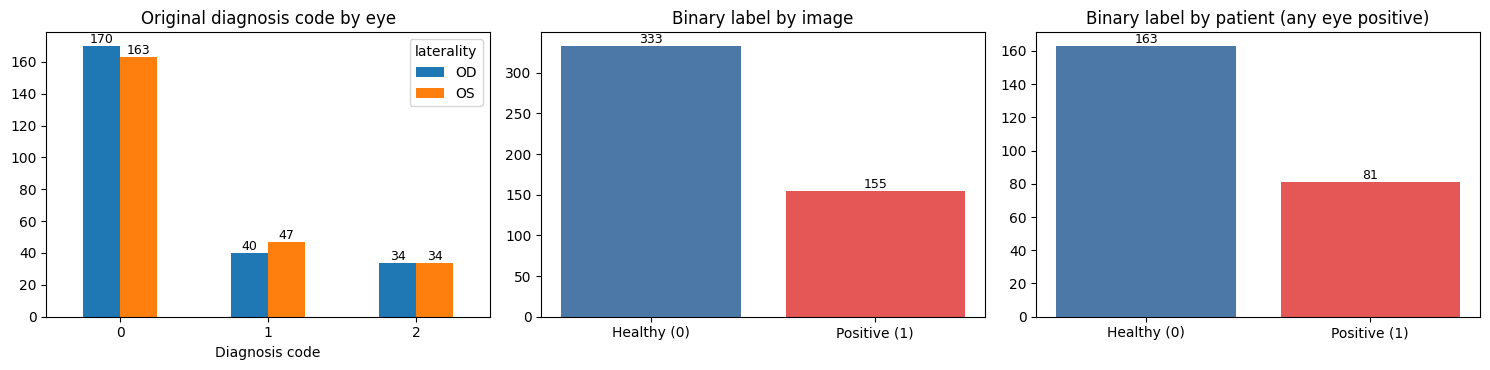

In [7]:
assert AUDIT_PASSED, "Audit did not pass - stop."
pat = META.groupby("patient_id").agg(n_eyes=("filename", "count"), n_pos_eyes=("binary_label", "sum"), any_pos=("binary_label", "max"))
print(f"Patients: {len(pat)} | patients with 2 eyes: {(pat.n_eyes==2).sum()} | with 1 eye: {(pat.n_eyes==1).sum()}")
print("Eye-pattern per patient (n_eyes, n_positive_eyes) -> count:\n", pat.groupby(["n_eyes", "n_pos_eyes"]).size().to_string())
disc = int(((pat.n_eyes == 2) & (pat.n_pos_eyes == 1)).sum())
print(f"Patients whose two eyes have DIFFERENT binary labels: {disc} (eye-level labels are kept as-is)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ct = pd.crosstab(META["original_diagnosis"], META["laterality"]); ct.plot.bar(ax=ax[0], rot=0); ax[0].set_title("Original diagnosis code by eye"); ax[0].set_xlabel("Diagnosis code")
vc = META["binary_label"].value_counts().sort_index(); ax[1].bar(["Healthy (0)", "Positive (1)"], [vc.get(0, 0), vc.get(1, 0)], color=["#4C78A8", "#E45756"]); ax[1].set_title("Binary label by image")
pc = pat["any_pos"].value_counts().sort_index(); ax[2].bar(["Healthy (0)", "Positive (1)"], [pc.get(0, 0), pc.get(1, 0)], color=["#4C78A8", "#E45756"]); ax[2].set_title("Binary label by patient (any eye positive)")
for a in ax:
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(WORK / "class_distribution.png", dpi=130); plt.show()

## 9. Configuration and reproducibility

**One central configuration** drives everything. Rationale for the main settings:
- `AdamW`, `lr = 5e-5`, `weight_decay = 1e-2`, cosine decay over the 5 epochs: a single conservative fine-tuning setting that is stable for CNNs, ViT/DeiT/Swin and the large VGG/AlexNet heads. It is deliberately **not tuned per model** (no hyper-parameter tuning on held-out folds).
- `grad_clip = 1.0`: justified by the occasional gradient spikes of transformer models trained for a few epochs with fp16 autocast and small batches; applied identically to all models (after un-scaling).
- `batch_size = 8` (training) — safe on a T4 for every model at 299×299; `drop_last=True` for training avoids a size-1 BatchNorm batch.
- Loss: `CrossEntropyLoss` with two logits (equivalent to binary cross-entropy). Class weights are **off** by default (`use_class_weights`); if enabled they are computed from the *training fold only*.
- Determinism: all seeds fixed to 42 (Python, NumPy, PyTorch, CUDA, split, DataLoader generator and workers); `cudnn.deterministic=True`, `benchmark=False`, `use_deterministic_algorithms(True, warn_only=True)` — some CUDA ops (e.g. adaptive pooling backward) have no deterministic implementation, so **bitwise reproducibility is not guaranteed** and deterministic mode costs some speed.

In [8]:
CFG = dict(
    seed=42, n_folds=5, folds_to_run=None,            # None -> all folds; e.g. [0] for a quick partial run
    models=None,                                        # None -> all 12 registered models
    epochs=5, img_size=299,
    batch_size=8, eval_batch_size=16, num_workers=2,
    lr=5e-5, weight_decay=1e-2, grad_clip=1.0, use_class_weights=False,
    amp=AMP_ENABLED, deterministic=True, threshold=0.5,
    hflip_p=0.5, rotation_deg=10, brightness=0.10, contrast=0.10,
    ckpt_dtype="float16",                               # weights stored in fp16 to halve disk usage (~8 GB for all runs in fp16)
    save_best_val_ckpt=True,                            # DIAGNOSTIC ONLY - never used for the reported metrics
    retry_smaller_batch_on_oom=True,
    resume=True, resume_source=None,                    # resume_source: path of a previous output dir (e.g. /kaggle/input/<my-output>)
)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if CFG["deterministic"]:
        torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
        torch.use_deterministic_algorithms(True, warn_only=True)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

warnings.filterwarnings("ignore", message=".*does not have a deterministic implementation.*")
seed_everything(CFG["seed"])
print(json.dumps(CFG, indent=2))

{
  "seed": 42,
  "n_folds": 5,
  "folds_to_run": null,
  "models": null,
  "epochs": 5,
  "img_size": 299,
  "batch_size": 8,
  "eval_batch_size": 16,
  "num_workers": 2,
  "lr": 5e-05,
  "weight_decay": 0.01,
  "grad_clip": 1.0,
  "use_class_weights": false,
  "amp": true,
  "deterministic": true,
  "threshold": 0.5,
  "hflip_p": 0.5,
  "rotation_deg": 10,
  "brightness": 0.1,
  "contrast": 0.1,
  "ckpt_dtype": "float16",
  "save_best_val_ckpt": true,
  "retry_smaller_batch_on_oom": true,
  "resume": true,
  "resume_source": null
}


## 10. Patient-level five-fold split creation and leakage assertions

`StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` with **patient ID as the group**, so both eyes of a patient are always in the same fold.

**Patient-level stratification target (documented rule):** a patient's target is `1` if *any* of their eyes is Positive, else `0`; this value is attached to each of the patient's images *only* as the stratification variable. Eye-level labels are untouched, and the two eyes of a patient may differ. The assertions below verify there is no patient overlap between training and validation in any fold.

In [9]:
assert AUDIT_PASSED
META = META.reset_index(drop=True)
patient_target = META.groupby("patient_id")["binary_label"].max()
META["strat_target"] = META["patient_id"].map(patient_target).astype(int)

sgkf = StratifiedGroupKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=CFG["seed"])
META["fold"] = -1
for k, (_tr, va) in enumerate(sgkf.split(META, y=META["strat_target"], groups=META["patient_id"])):
    META.loc[va, "fold"] = k
assert (META["fold"] >= 0).all(), "some images were not assigned to a validation fold"

FOLD_IDX = {k: (META.index[META.fold != k].to_numpy(), META.index[META.fold == k].to_numpy()) for k in range(CFG["n_folds"])}
rows = []
for k, (tr, va) in FOLD_IDX.items():
    tr_p, va_p = set(META.loc[tr, "patient_id"]), set(META.loc[va, "patient_id"])
    assert tr_p.isdisjoint(va_p), f"PATIENT LEAKAGE in fold {k}: {sorted(tr_p & va_p)[:10]}"
    assert set(tr).isdisjoint(set(va)) and len(tr) + len(va) == len(META)
    rows.append(dict(fold=k, val_patients=len(va_p), val_images=len(va), val_healthy=int((META.loc[va, "binary_label"] == 0).sum()),
                     val_positive=int((META.loc[va, "binary_label"] == 1).sum()), train_patients=len(tr_p), train_images=len(tr),
                     train_healthy=int((META.loc[tr, "binary_label"] == 0).sum()), train_positive=int((META.loc[tr, "binary_label"] == 1).sum())))
assert sorted(np.concatenate([v for _, v in FOLD_IDX.values()]).tolist()) == list(range(len(META))), "each image must be validated exactly once"
assert sum(r["val_patients"] for r in rows) == META["patient_id"].nunique(), "each patient must be validated in exactly one fold"
FOLD_TABLE = pd.DataFrame(rows); display(FOLD_TABLE)
for r in rows:
    if r["val_healthy"] == 0 or r["val_positive"] == 0:
        warnings.warn(f"fold {r['fold']} validation set has a single class: AUROC will be NaN for that fold")
print("Leakage assertions passed for all folds.")

LABELS = META["binary_label"].to_numpy(dtype=np.int64)
SPLIT_HASH = hashlib.sha1("|".join(f"{f}:{k}:{l}" for f, k, l in zip(META.filename, META.fold, META.binary_label)).encode()).hexdigest()[:12]
VAL_SIG = {k: hashlib.sha1("|".join(sorted(META.loc[v, "filename"])).encode()).hexdigest()[:12] for k, (_, v) in FOLD_IDX.items()}
META[["filename", "patient_id", "laterality", "binary_label", "strat_target", "fold"]].to_csv(WORK / "fold_assignments.csv", index=False)
print("Split hash:", SPLIT_HASH, "| saved fold_assignments.csv")

,fold,val_patients,val_images,val_healthy,val_positive,train_patients,train_images,train_healthy,train_positive
0,0,49,98,63,35,195,390,270,120
1,1,49,98,64,34,195,390,269,121
2,2,49,98,71,27,195,390,262,128
3,3,49,98,66,32,195,390,267,123
4,4,48,96,69,27,196,392,264,128


Leakage assertions passed for all folds.
Split hash: 220dfae8297b | saved fold_assignments.csv


## 11. Model registry and pretrained-weight validation

Exactly 12 architectures. torchvision models use the modern `weights=<Enum>.DEFAULT` API (the enum name is logged). **If pretrained weights cannot be obtained, the model is marked `not_run` — there is never a silent fall-back to random initialisation.**

Documented model-specific handling
- **Head:** the final linear layer is replaced by a 2-logit layer (`CrossEntropyLoss`).
- **Inception-v3:** torchvision enables `transform_input=True` with pretrained weights (so standard ImageNet normalisation is correct); the **auxiliary classifier is disabled** (`aux_logits=False`, `AuxLogits=None`), so the model returns plain logits in train mode.
- **ViT-B/16 @ 299:** torchvision fixes `image_size=224`; the positional embedding is bicubically interpolated 14×14 → 18×18 and `image_size` set to 299 (patch embedding at stride 16 yields 18×18 patches and ignores the last 11 pixel rows/columns). This is a documented adaptation.
- **DeiT-Tiny:** not available in torchvision → `timm` `deit_tiny_patch16_224.fb_in1k` (official ImageNet-1k weights from the Hugging Face hub), created with `img_size=299` so timm resamples the positional embedding.
- **Swin-T / ConvNeXt / others** accept 299×299 natively (torchvision's Swin pads internally to the window size).
- **Normalisation:** ImageNet mean/std taken from each weight's own transform metadata (timm: from `pretrained_cfg`).
- All parameters are fine-tuned (no frozen layers).

In [10]:
assert AUDIT_PASSED
import torchvision.models as tvm

def _swap(parent, attr, n_out=2):
    old = getattr(parent, attr) if not isinstance(attr, int) else parent[attr]
    new = nn.Linear(old.in_features, n_out)
    if isinstance(attr, int): parent[attr] = new
    else: setattr(parent, attr, new)

def _tv_meta(w):
    t = w.transforms(); return list(t.mean), list(t.std)

def adapt_torchvision_vit_resolution(m, new_size):
    old_grid, new_grid = m.image_size // m.patch_size, new_size // m.patch_size
    pe = m.encoder.pos_embedding.data                       # [1, 1 + g*g, D]
    cls, grid = pe[:, :1], pe[:, 1:]
    D = pe.shape[-1]
    grid = grid.reshape(1, old_grid, old_grid, D).permute(0, 3, 1, 2)
    grid = F.interpolate(grid.float(), size=(new_grid, new_grid), mode="bicubic", align_corners=False)
    grid = grid.permute(0, 2, 3, 1).reshape(1, new_grid * new_grid, D)
    m.encoder.pos_embedding = nn.Parameter(torch.cat([cls, grid], dim=1))
    m.image_size = new_size
    return m

def _build_tv(fn_name, weights_enum, head):
    def build():
        w = weights_enum.DEFAULT
        m = getattr(tvm, fn_name)(weights=w)
        head(m)
        mean, std = _tv_meta(w)
        return m, dict(weights=f"{weights_enum.__name__}.DEFAULT ({w.name})", mean=mean, std=std, source="torchvision")
    return build

def _head_inception(m):
    m.aux_logits = False; m.AuxLogits = None; _swap(m, "fc")
def _head_vit(m):
    _swap(m.heads, "head"); adapt_torchvision_vit_resolution(m, CFG["img_size"])

def _build_deit():
    if timm is None: raise RuntimeError("timm is not installed")
    how = "pos-embed resampled to 299"
    try:
        m = timm.create_model("deit_tiny_patch16_224.fb_in1k", pretrained=True, num_classes=2, img_size=CFG["img_size"])
    except AssertionError:      # some timm versions refuse sizes not divisible by the patch size -> documented fallback (still 299 input)
        m = timm.create_model("deit_tiny_patch16_224.fb_in1k", pretrained=True, num_classes=2, dynamic_img_size=True, dynamic_img_pad=True)
        how = "dynamic pos-embed interpolation + padding to 304 (fallback, timm refused img_size=299)"
    pc = getattr(m, "pretrained_cfg", {}) or {}
    mean, std = list(pc.get("mean", (0.485, 0.456, 0.406))), list(pc.get("std", (0.229, 0.224, 0.225)))
    return m, dict(weights=f"timm deit_tiny_patch16_224.fb_in1k (ImageNet-1k, {how})", mean=mean, std=std, source="timm")

REGISTRY = OrderedDict([
    ("ResNet50",          _build_tv("resnet50", tvm.ResNet50_Weights, lambda m: _swap(m, "fc"))),
    ("DenseNet121",       _build_tv("densenet121", tvm.DenseNet121_Weights, lambda m: _swap(m, "classifier"))),
    ("EfficientNet-B0",   _build_tv("efficientnet_b0", tvm.EfficientNet_B0_Weights, lambda m: _swap(m.classifier, 1))),
    ("MobileNetV3-Large", _build_tv("mobilenet_v3_large", tvm.MobileNet_V3_Large_Weights, lambda m: _swap(m.classifier, 3))),
    ("ConvNeXt-Tiny",     _build_tv("convnext_tiny", tvm.ConvNeXt_Tiny_Weights, lambda m: _swap(m.classifier, 2))),
    ("Inception-v3",      _build_tv("inception_v3", tvm.Inception_V3_Weights, _head_inception)),
    ("ViT-B/16",          _build_tv("vit_b_16", tvm.ViT_B_16_Weights, _head_vit)),
    ("DeiT-Tiny",         _build_deit),
    ("Swin-Tiny",         _build_tv("swin_t", tvm.Swin_T_Weights, lambda m: _swap(m, "head"))),
    ("VGG16",             _build_tv("vgg16", tvm.VGG16_Weights, lambda m: _swap(m.classifier, 6))),
    ("RegNet-Y-400MF",    _build_tv("regnet_y_400mf", tvm.RegNet_Y_400MF_Weights, lambda m: _swap(m, "fc"))),
    ("AlexNet",           _build_tv("alexnet", tvm.AlexNet_Weights, lambda m: _swap(m.classifier, 6))),
])
assert len(REGISTRY) == 12
MODELS = list(CFG["models"] or REGISTRY.keys())
assert all(m in REGISTRY for m in MODELS), "unknown model name in CFG['models']"

def build_model(name):
    """Always returns a model with pretrained weights loaded; raises if they cannot be obtained (no random-init fallback)."""
    return REGISTRY[name]()

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

MODEL_INFO, MODEL_STATUS, rows = {}, {}, []
for name in tqdm(MODELS, desc="validating pretrained weights"):
    try:
        m, info = build_model(name)
        tot, trn = count_params(m)
        info.update(params_total=tot, params_trainable=trn)
        MODEL_INFO[name] = info; MODEL_STATUS[name] = ("ready", "")
        rows.append(dict(model=name, source=info["source"], weights=info["weights"], params_total=tot, params_trainable=trn, init="pretrained weights loaded",
                         norm_mean=np.round(info["mean"], 3).tolist(), norm_std=np.round(info["std"], 3).tolist(), status="ready"))
        del m
    except Exception as e:
        MODEL_STATUS[name] = ("not_run", f"{type(e).__name__}: {str(e)[:300]}")
        rows.append(dict(model=name, source="-", weights="UNAVAILABLE", params_total=None, params_trainable=None, init="NOT initialised (no random fallback)", status=f"not_run: {type(e).__name__}"))
        print(f"  !! {name}: pretrained weights unavailable -> marked NOT RUN ({type(e).__name__}: {str(e)[:150]})")
    gc.collect()
MODEL_TABLE = pd.DataFrame(rows); display(MODEL_TABLE)
READY_MODELS = [m for m in MODELS if MODEL_STATUS[m][0] == "ready"]
if not READY_MODELS:
    raise RuntimeError("No model could load pretrained weights. Enable Internet in the notebook settings (first run) or attach the weights as an input.")
print(f"{len(READY_MODELS)}/{len(MODELS)} models ready:", READY_MODELS)

validating pretrained weights:   0%|          | 0/12 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth



  0%|          | 0.00/97.8M [00:00<?, ?B/s]
 21%|██        | 20.5M/97.8M [00:00<00:00, 215MB/s]
 45%|████▌     | 44.4M/97.8M [00:00<00:00, 235MB/s]
 68%|██████▊   | 66.9M/97.8M [00:00<00:00, 212MB/s]
100%|██████████| 97.8M/97.8M [00:00<00:00, 212MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth



  0%|          | 0.00/30.8M [00:00<?, ?B/s]
100%|██████████| 30.8M/30.8M [00:00<00:00, 222MB/s]


...


100%|██████████| 16.8M/16.8M [00:00<00:00, 201MB/s]


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth



  0%|          | 0.00/233M [00:00<?, ?B/s]
  7%|▋         | 16.5M/233M [00:00<00:01, 172MB/s]
 15%|█▍        | 34.4M/233M [00:00<00:01, 180MB/s]
 23%|██▎       | 52.6M/233M [00:00<00:01, 185MB/s]
 30%|███       | 70.4M/233M [00:00<00:00, 185MB/s]
 38%|███▊      | 88.5M/233M [00:00<00:00, 187MB/s]
 46%|████▌     | 106M/233M [00:00<00:00, 187MB/s] 
 53%|█████▎    | 124M/233M [00:00<00:00, 186MB/s]
 61%|██████    | 142M/233M [00:00<00:00, 180MB/s]
 69%|██████▊   | 160M/233M [00:00<00:00, 181MB/s]
 78%|███████▊  | 181M/233M [00:01<00:00, 193MB/s]
 87%|████████▋ | 202M/233M [00:01<00:00, 202MB/s]
100%|██████████| 233M/233M [00:01<00:00, 191MB/s]


,model,source,weights,params_total,params_trainable,init,norm_mean,norm_std,status
0,ResNet50,torchvision,ResNet50_Weights.DEFAULT (IMAGENET1K_V2),23512130,23512130,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
1,DenseNet121,torchvision,DenseNet121_Weights.DEFAULT (IMAGENET1K_V1),6955906,6955906,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
2,EfficientNet-B0,torchvision,EfficientNet_B0_Weights.DEFAULT (IMAGENET1K_V1),4010110,4010110,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
3,MobileNetV3-Large,torchvision,MobileNet_V3_Large_Weights.DEFAULT (IMAGENET1K_V2),4204594,4204594,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
4,ConvNeXt-Tiny,torchvision,ConvNeXt_Tiny_Weights.DEFAULT (IMAGENET1K_V1),27821666,27821666,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
5,Inception-v3,torchvision,Inception_V3_Weights.DEFAULT (IMAGENET1K_V1),21789666,21789666,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
6,ViT-B/16,torchvision,ViT_B_16_Weights.DEFAULT (IMAGENET1K_V1),85898498,85898498,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
7,DeiT-Tiny,timm,"timm deit_tiny_patch16_224.fb_in1k (ImageNet-1k, pos-embed resampled to 299)",5549378,5549378,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
8,Swin-Tiny,torchvision,Swin_T_Weights.DEFAULT (IMAGENET1K_V1),27520892,27520892,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready
9,VGG16,torchvision,VGG16_Weights.DEFAULT (IMAGENET1K_V1),134268738,134268738,pretrained weights loaded,"[0.485, 0.456, 0.406]","[0.229, 0.224, 0.225]",ready


12/12 models ready: ['ResNet50', 'DenseNet121', 'EfficientNet-B0', 'MobileNetV3-Large', 'ConvNeXt-Tiny', 'Inception-v3', 'ViT-B/16', 'DeiT-Tiny', 'Swin-Tiny', 'VGG16', 'RegNet-Y-400MF', 'AlexNet']


## 12. Dataset, transforms and DataLoaders

- **Preprocessing:** RGB conversion → resize preserving the aspect ratio (longer side → 299) → **black padding to a 299×299 square (letterbox)**. Cropping would risk removing the periphery/optic-disc region and stretching would distort anatomy; padding keeps the full fundus without distortion. Preprocessed images are **cached as `uint8` in RAM** (488×299×299×3 ≈ 130 MB) — this involves no statistics, so it cannot leak validation information.
- **Training augmentation only** (conservative): horizontal flip (p = 0.5; a mirrored fundus resembles the fellow eye), rotation ±10° (black fill), brightness/contrast ±10 %.
- **Validation:** deterministic — no augmentation; only `float` conversion and ImageNet normalisation (fixed constants, not computed from any fold).
- Any unreadable image is a **fatal error** (no replacement or duplication).

caching 299x299 letterboxed images:   0%|          | 0/488 [00:00<?, ?it/s]

Cache: (488, 299, 299, 3), 125 MB, dtype uint8


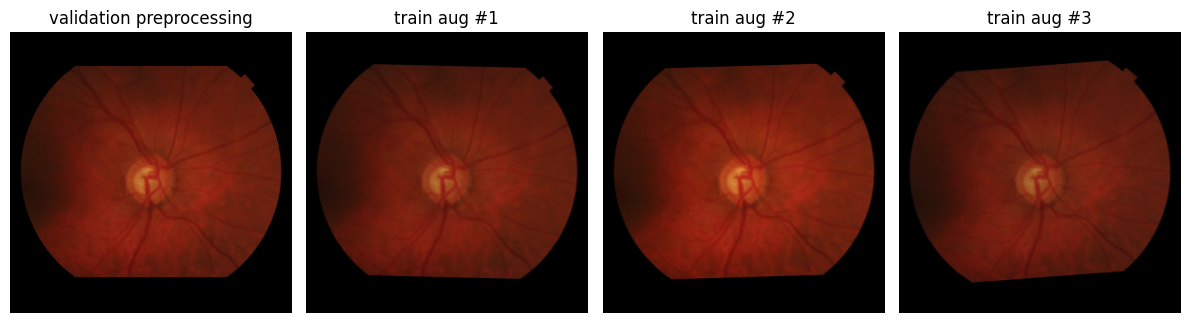

In [11]:
assert AUDIT_PASSED
from torchvision.transforms import v2
from torchvision.transforms import InterpolationMode

def load_letterboxed(path, size):
    with Image.open(path) as im:
        im = im.convert("RGB")
        w, h = im.size; s = size / max(w, h)
        nw, nh = max(1, round(w * s)), max(1, round(h * s))
        im = im.resize((nw, nh), Image.BICUBIC)
        canvas = Image.new("RGB", (size, size), (0, 0, 0))
        canvas.paste(im, ((size - nw) // 2, (size - nh) // 2))
        return np.asarray(canvas, dtype=np.uint8)

bad = []
IMG_CACHE = np.zeros((len(META), CFG["img_size"], CFG["img_size"], 3), dtype=np.uint8)
for i, p in enumerate(tqdm(META["image_path"], desc="caching 299x299 letterboxed images")):
    try: IMG_CACHE[i] = load_letterboxed(p, CFG["img_size"])
    except Exception as e: bad.append((p, repr(e)))
if bad:
    raise AuditFailure(f"{len(bad)} unreadable image(s); not replaced or skipped: {bad[:5]}")
print(f"Cache: {IMG_CACHE.shape}, {IMG_CACHE.nbytes/1024**2:.0f} MB, dtype {IMG_CACHE.dtype}")

def make_transform(mean, std, train):
    ops = []
    if train:
        ops += [v2.RandomHorizontalFlip(p=CFG["hflip_p"]),
                v2.RandomRotation(degrees=CFG["rotation_deg"], interpolation=InterpolationMode.BILINEAR, fill=0),
                v2.ColorJitter(brightness=CFG["brightness"], contrast=CFG["contrast"])]
    ops += [v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean=mean, std=std)]
    return v2.Compose(ops)

class FundusDataset(Dataset):
    def __init__(self, cache, labels, idx, transform):
        self.cache, self.labels, self.idx, self.transform = cache, labels, np.asarray(idx), transform
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = int(self.idx[i])
        x = torch.from_numpy(self.cache[j]).permute(2, 0, 1).contiguous()      # uint8 CHW
        return self.transform(x), int(self.labels[j]), j                       # j = row in META (for prediction mapping)

def make_loader(idx, train, batch_size, mean, std):
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    nw = CFG["num_workers"]
    return DataLoader(FundusDataset(IMG_CACHE, LABELS, idx, make_transform(mean, std, train)), batch_size=batch_size,
                      shuffle=train, drop_last=train, num_workers=nw, pin_memory=(DEVICE.type == "cuda"),
                      persistent_workers=(nw > 0), worker_init_fn=seed_worker if nw > 0 else None, generator=g)

# visual sanity check of train augmentation vs. deterministic validation preprocessing (one fold-0 training image)
_mean, _std = MODEL_INFO[READY_MODELS[0]]["mean"], MODEL_INFO[READY_MODELS[0]]["std"]
_ds_tr = FundusDataset(IMG_CACHE, LABELS, FOLD_IDX[0][0][:1], make_transform(_mean, _std, True))
_ds_va = FundusDataset(IMG_CACHE, LABELS, FOLD_IDX[0][0][:1], make_transform(_mean, _std, False))
def _show(t): return (t.permute(1, 2, 0) * torch.tensor(_std) + torch.tensor(_mean)).clamp(0, 1).numpy()
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
ax[0].imshow(_show(_ds_va[0][0])); ax[0].set_title("validation preprocessing")
for k in range(1, 4): ax[k].imshow(_show(_ds_tr[0][0])); ax[k].set_title(f"train aug #{k}")
[a.axis("off") for a in ax]; plt.tight_layout(); plt.show()

## 13. Reusable training and evaluation functions

A **single** training loop and a single evaluation function serve all models.
- Mixed precision via `torch.autocast` + `torch.amp.GradScaler` (disabled automatically on CPU); `zero_grad(set_to_none=True)`; `model.train()` / `model.eval()`; `torch.inference_mode()` for validation; gradient clipping after un-scaling.
- **Timing:** CUDA is synchronised before/after every timed region. *Training duration* = summed wall time of the training phases of all epochs. *Inference time* = summed forward-pass time over the whole validation fold of the **final epoch** (data loading excluded, model already warmed up, same autocast setting as validation), *latency per image* = that time ÷ number of validation images (batch size = `eval_batch_size`, so it is a batched-throughput latency, not a single-image latency).
- **Metrics:** threshold `0.5` on P(positive): predict positive if `p ≥ 0.5`. Undefined quantities are **NaN, never 0** (AUROC with one class; sensitivity/specificity with an empty class; precision with no predicted positives). Confusion matrix order `[[TN, FP], [FN, TP]]`.
- **Run directory** `runs/<model>/fold<k>/`: `final.pt`, optional `best_val_auroc.pt` (diagnostic), `history.csv`, `val_predictions.csv`, `metrics.json`, and `done.json` (written last; marks a run complete). Resume compares a signature of config + split + validation patients (and the checkpoint metadata) before skipping a run.
- **OOM policy:** record → free memory → retry once with half the batch size → otherwise mark the run failed (`failed.json`) and continue. Other exceptions are recorded as failed runs too; failed runs never contribute metrics.

In [12]:
assert AUDIT_PASSED
RUNS_DIR = WORK / "runs"; RUNS_DIR.mkdir(exist_ok=True)
EVENT_LOG = []
def log_event(model, fold, event, detail=""):
    EVENT_LOG.append(dict(time_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"), model=model, fold=fold, event=event, detail=str(detail)[:500]))
    print(f"  [{event}] {model} fold {fold}: {str(detail)[:200]}")

def slug(s): return re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")
def run_dir(name, fold): return RUNS_DIR / slug(name) / f"fold{fold}"
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()
def free_memory():
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

SIG_KEYS = ["seed", "n_folds", "epochs", "img_size", "lr", "weight_decay", "grad_clip", "use_class_weights", "threshold", "hflip_p",
            "rotation_deg", "brightness", "contrast", "ckpt_dtype", "save_best_val_ckpt", "deterministic"]
TRAIN_SIG = hashlib.sha1((json.dumps({k: CFG[k] for k in SIG_KEYS}, sort_keys=True) + f"|amp={AMP_ENABLED}|split={SPLIT_HASH}").encode()).hexdigest()[:12]
print("Training/config/split signature:", TRAIN_SIG)

def nan_to_none(o):
    if isinstance(o, dict): return {k: nan_to_none(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [nan_to_none(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.integer): return int(o)
    return o

def write_json_atomic(path, obj):
    tmp = Path(str(path) + ".tmp"); tmp.write_text(json.dumps(nan_to_none(obj), indent=2)); os.replace(tmp, path)
def torch_save_atomic(obj, path):
    tmp = Path(str(path) + ".tmp"); torch.save(obj, tmp); os.replace(tmp, path)

def unwrap_logits(out):
    if isinstance(out, torch.Tensor): return out
    if hasattr(out, "logits"): return out.logits
    if isinstance(out, (tuple, list)): return out[0]
    raise TypeError(f"unexpected model output type {type(out)}")

def compute_metrics(y_true, prob, thr=0.5):
    y_true = np.asarray(y_true).astype(int); prob = np.asarray(prob, dtype=float)
    if not np.all(np.isfinite(prob)): raise FloatingPointError("non-finite probabilities (diverged model)")
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    div = lambda a, b: float(a) / float(b) if b > 0 else float("nan")
    sens, spec, prec = div(tp, tp + fn), div(tn, tn + fp), div(tp, tp + fp)
    both = not (np.isnan(sens) or np.isnan(spec))
    auroc = float(roc_auc_score(y_true, prob)) if len(np.unique(y_true)) == 2 else float("nan")
    return dict(accuracy=div(tp + tn, len(y_true)), balanced_accuracy=(sens + spec) / 2 if both else float("nan"), sensitivity=sens,
                specificity=spec, precision=prec, f1=div(2 * tp, 2 * tp + fp + fn), auroc=auroc, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

CORE_METRICS = ["accuracy", "balanced_accuracy", "sensitivity", "specificity", "precision", "f1", "auroc"]

def train_one_epoch(model, loader, optimizer, scaler, criterion):
    model.train()
    total, n = torch.zeros((), device=DEVICE), 0
    for x, y, _ in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            logits = unwrap_logits(model(x))
        loss = criterion(logits.float(), y)
        if not torch.isfinite(loss): raise FloatingPointError("non-finite training loss")
        scaler.scale(loss).backward()
        if CFG["grad_clip"]:
            scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update()
        total += loss.detach() * x.size(0); n += x.size(0)
    return float(total.item() / max(n, 1))

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    probs, ys, js, loss_sum, fwd = [], [], [], 0.0, 0.0
    for x, y, j in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        sync(); t0 = time.perf_counter()
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            logits = unwrap_logits(model(x))
        sync(); fwd += time.perf_counter() - t0
        logits = logits.float()
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()          # unweighted mean CE on validation
        probs.append(torch.softmax(logits, 1)[:, 1].cpu()); ys.append(y.cpu()); js.append(j)
    prob, y_true, j = torch.cat(probs).numpy(), torch.cat(ys).numpy(), torch.cat(js).numpy()
    return dict(val_loss=loss_sum / len(y_true), prob=prob, y_true=y_true, idx=j, forward_time_s=fwd, n=len(y_true))

def state_for_ckpt(model):
    dt = torch.float16 if CFG["ckpt_dtype"] == "float16" else torch.float32
    return {k: (v.detach().to("cpu", dt) if v.is_floating_point() else v.detach().cpu()) for k, v in model.state_dict().items()}

def py(o):  # plain-python version for torch.load(weights_only=True)
    if isinstance(o, dict): return {k: py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [py(v) for v in o]
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer): return int(o)
    return o

def read_ckpt_meta(path):
    ck = torch.load(path, map_location="cpu", weights_only=True, mmap=True)
    meta = ck["meta"]; del ck
    return meta

def check_resume(name, fold):
    rd = run_dir(name, fold); dj = rd / "done.json"
    if not dj.exists(): return False, "no done.json"
    try: done = json.loads(dj.read_text())
    except Exception as e: return False, f"unreadable done.json ({e})"
    problems = []
    if done.get("signature") != TRAIN_SIG: problems.append("config/split signature differs")
    if done.get("model") != name or done.get("fold") != fold: problems.append("model/fold mismatch")
    if done.get("val_signature") != VAL_SIG[fold]: problems.append("validation patients differ")
    problems += [f"missing file {f}" for f in done.get("files", []) if not (rd / f).exists()]
    if not problems:
        try:
            meta = read_ckpt_meta(rd / "final.pt")
            if meta.get("signature") != TRAIN_SIG or meta.get("model") != name or meta.get("fold") != fold: problems.append("checkpoint metadata incompatible")
        except Exception as e: problems.append(f"checkpoint unreadable ({type(e).__name__})")
    return (not problems), "; ".join(problems)

def import_previous_runs(src):
    src = Path(src); n = 0
    base = src / "runs" if (src / "runs").exists() else src
    for dj in base.rglob("done.json"):
        dest = RUNS_DIR / dj.parent.relative_to(base)
        if not (dest / "done.json").exists():
            shutil.copytree(dj.parent, dest, dirs_exist_ok=True); n += 1
    print(f"Imported {n} completed run(s) from {src}")
if CFG["resume_source"]: import_previous_runs(CFG["resume_source"])

Training/config/split signature: abaec56526ae


In [13]:
def execute_run(name, fold, batch_size):
    """One model x one fold. Raises on any failure (handled by run_with_recovery)."""
    rd = run_dir(name, fold); rd.mkdir(parents=True, exist_ok=True)
    for stale in ("done.json", "failed.json"): (rd / stale).unlink(missing_ok=True)
    seed_everything(CFG["seed"])
    tr_idx, va_idx = FOLD_IDX[fold]
    model, info = build_model(name); model = model.to(DEVICE)
    mean, std = MODEL_INFO[name]["mean"], MODEL_INFO[name]["std"]
    train_loader = make_loader(tr_idx, True, batch_size, mean, std)
    val_loader = make_loader(va_idx, False, CFG["eval_batch_size"], mean, std)
    weight = None
    if CFG["use_class_weights"]:                                   # computed from the TRAINING fold only
        cnt = np.bincount(LABELS[tr_idx], minlength=2); weight = torch.tensor(len(tr_idx) / (2.0 * cnt), dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP_ENABLED)

    history, best_score, best_state, best_epoch, train_time = [], -float("inf"), None, None, 0.0
    for epoch in range(1, CFG["epochs"] + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        sync(); t0 = time.perf_counter()
        tr_loss = train_one_epoch(model, train_loader, optimizer, scaler, criterion)
        sync(); t_train = time.perf_counter() - t0
        scheduler.step()
        t1 = time.perf_counter(); ev = evaluate(model, val_loader); t_eval = time.perf_counter() - t1
        m = compute_metrics(ev["y_true"], ev["prob"], CFG["threshold"])
        train_time += t_train
        history.append(dict(model=name, fold=fold, epoch=epoch, lr=lr_now, train_loss=tr_loss, val_loss=ev["val_loss"],
                            **{k: m[k] for k in CORE_METRICS}, train_time_s=t_train, eval_time_s=t_eval, epoch_time_s=t_train + t_eval))
        # diagnostic "best epoch" tracking (selection on the held-out fold -> NEVER used for reported metrics)
        score = m["auroc"] if np.isfinite(m["auroc"]) else -ev["val_loss"]
        if CFG["save_best_val_ckpt"] and score > best_score:
            best_score, best_epoch, best_state = score, epoch, state_for_ckpt(model)
        print(f"  [{name} | fold {fold} | ep {epoch}/{CFG['epochs']}] train_loss {tr_loss:.4f} val_loss {ev['val_loss']:.4f} "
              f"AUROC {m['auroc']:.4f} bAcc {m['balanced_accuracy']:.4f} sens {m['sensitivity']:.3f} spec {m['specificity']:.3f} ({t_train + t_eval:.1f}s)")

    # ---- reported result = FINAL epoch (no selection on the held-out fold) ----
    final_ev, final_m = ev, m
    meta_common = py(dict(model=name, fold=fold, seed=CFG["seed"], signature=TRAIN_SIG, batch_size=batch_size, torch=str(torch.__version__),
                          torchvision=str(torchvision.__version__), config={k: CFG[k] for k in SIG_KEYS}, weights=MODEL_INFO[name]["weights"], ckpt_dtype=CFG["ckpt_dtype"]))
    torch_save_atomic(dict(meta=dict(meta_common, epoch=CFG["epochs"], selection="final_epoch (used for reported metrics)", metrics=py(final_m)),
                           state_dict=state_for_ckpt(model)), rd / "final.pt")
    files = ["final.pt", "history.csv", "val_predictions.csv", "metrics.json"]
    if best_state is not None:
        torch_save_atomic(dict(meta=dict(meta_common, epoch=best_epoch, selection="best validation AUROC epoch - DIAGNOSTIC ONLY (selected on held-out fold; not used for reported metrics)"),
                               state_dict=best_state), rd / "best_val_auroc.pt")
        files.append("best_val_auroc.pt")
    pd.DataFrame(history).to_csv(rd / "history.csv", index=False)
    sub = META.loc[final_ev["idx"]]
    pd.DataFrame(dict(model=name, fold=fold, filename=sub["filename"].values, patient_id=sub["patient_id"].values, laterality=sub["laterality"].values,
                      original_diagnosis=sub["original_diagnosis"].values, y_true=final_ev["y_true"], prob_positive=final_ev["prob"],
                      y_pred=(final_ev["prob"] >= CFG["threshold"]).astype(int))).to_csv(rd / "val_predictions.csv", index=False)
    result = dict(model=name, fold=fold, status="complete", n_train_images=len(tr_idx), n_val_images=len(va_idx),
                  n_val_positive=int((final_ev["y_true"] == 1).sum()), n_val_negative=int((final_ev["y_true"] == 0).sum()), **final_m,
                  confusion_matrix=f"[[{final_m['tn']}, {final_m['fp']}], [{final_m['fn']}, {final_m['tp']}]]",
                  train_time_s=train_time, inference_time_s=final_ev["forward_time_s"], latency_ms_per_image=1000 * final_ev["forward_time_s"] / final_ev["n"],
                  epochs=CFG["epochs"], batch_size_used=batch_size, threshold=CFG["threshold"], best_epoch_by_val_auroc_diagnostic=best_epoch,
                  params_total=MODEL_INFO[name]["params_total"], params_trainable=MODEL_INFO[name]["params_trainable"])
    write_json_atomic(rd / "metrics.json", result)
    write_json_atomic(rd / "done.json", dict(status="complete", model=name, fold=fold, signature=TRAIN_SIG, val_signature=VAL_SIG[fold],
                                             batch_size_used=batch_size, files=files, finished_utc=datetime.now(timezone.utc).isoformat(timespec="seconds")))
    del model, optimizer, train_loader, val_loader
    return result

def run_with_recovery(name, fold):
    if CFG["resume"]:
        ok, why = check_resume(name, fold)
        if ok: return dict(model=name, fold=fold, status="resumed")
        if (run_dir(name, fold) / "done.json").exists(): log_event(name, fold, "resume_rejected", why + " -> retraining")
    batch_sizes = [CFG["batch_size"]]
    if CFG["retry_smaller_batch_on_oom"] and CFG["batch_size"] // 2 >= 2: batch_sizes.append(CFG["batch_size"] // 2)
    reason = ""
    for attempt, bs in enumerate(batch_sizes):
        oom = False
        try:
            res = execute_run(name, fold, bs)
            if attempt > 0: log_event(name, fold, "completed_after_oom_retry", f"batch size {bs}")
            free_memory(); return res
        except torch.cuda.OutOfMemoryError as e:
            oom, reason = True, f"CUDA OOM at batch size {bs}: {str(e)[:150]}"
        except Exception as e:                                       # recoverable training error -> record, continue with other runs
            reason = f"{type(e).__name__}: {str(e)[:300]}"
            tb = traceback.format_exc(limit=4); log_event(name, fold, "run_failed", reason)
            rd = run_dir(name, fold); rd.mkdir(parents=True, exist_ok=True)
            write_json_atomic(rd / "failed.json", dict(status="failed", model=name, fold=fold, reason=reason, traceback=tb, batch_size=bs))
            free_memory(); return dict(model=name, fold=fold, status="failed", reason=reason)
        if oom:
            log_event(name, fold, "oom", reason); free_memory()
    rd = run_dir(name, fold); rd.mkdir(parents=True, exist_ok=True)
    write_json_atomic(rd / "failed.json", dict(status="failed", model=name, fold=fold, reason=reason, batch_size=batch_sizes[-1]))
    return dict(model=name, fold=fold, status="failed", reason=reason)
print("Training/evaluation functions defined.")

Training/evaluation functions defined.


## 14. Quick smoke test on a tiny subset (before the full run)

For **every ready model** this runs, on a few *training-fold-0* images only: the real DataLoader → forward pass → loss → backward → optimizer step (via the same `train_one_epoch` used later), an evaluation forward pass (output must have shape `[B, 2]`), and a checkpoint save/load round-trip in memory. A model that fails is marked `not_run` with the reason. The measured step times give a **rough, approximate** runtime estimate (excludes model construction, checkpoint I/O and run-to-run variance).

In [14]:
assert AUDIT_PASSED
def smoke_test(name, bs):
    seed_everything(CFG["seed"])
    model, _ = build_model(name); model = model.to(DEVICE)
    mean, std = MODEL_INFO[name]["mean"], MODEL_INFO[name]["std"]
    tr_idx = FOLD_IDX[0][0][: 3 * bs]; va_idx = FOLD_IDX[0][0][3 * bs: 5 * bs]           # training-fold images only
    tl, vl = make_loader(tr_idx, True, bs, mean, std), make_loader(va_idx, False, CFG["eval_batch_size"], mean, std)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP_ENABLED); crit = nn.CrossEntropyLoss()
    train_one_epoch(model, tl, opt, scaler, crit)                                         # warm-up (also proves fwd+loss+backward+step)
    sync(); t0 = time.perf_counter(); loss = train_one_epoch(model, tl, opt, scaler, crit); sync(); t_train = time.perf_counter() - t0
    assert np.isfinite(loss), "non-finite loss"
    assert any(p.grad is not None for p in model.parameters()), "backward produced no gradients"
    ev = evaluate(model, vl); sync()
    assert ev["prob"].shape[0] == len(va_idx) and np.all(np.isfinite(ev["prob"])) and np.all((ev["prob"] >= 0) & (ev["prob"] <= 1))
    with torch.inference_mode(): out = unwrap_logits(model.eval()(next(iter(vl))[0].to(DEVICE)))
    assert out.ndim == 2 and out.shape[1] == 2, f"expected [B,2] logits, got {tuple(out.shape)}"
    buf = io.BytesIO(); torch.save(dict(meta=dict(model=name), state_dict=state_for_ckpt(model)), buf); buf.seek(0)
    sd = torch.load(buf, map_location="cpu", weights_only=True)["state_dict"]
    model.load_state_dict({k: (v.float() if v.is_floating_point() else v) for k, v in sd.items()})
    n_steps = len(tr_idx) // bs
    est = dict(step_s=t_train / n_steps, eval_s_per_img=ev["forward_time_s"] / ev["n"])
    del model, opt, tl, vl; return est

smoke_rows = []
for name in tqdm(READY_MODELS, desc="smoke test"):
    try:
        est = smoke_test(name, CFG["batch_size"])
        smoke_rows.append(dict(model=name, smoke="OK", **est))
    except Exception as e:
        reason = f"smoke test failed: {type(e).__name__}: {str(e)[:250]}"
        MODEL_STATUS[name] = ("not_run", reason); smoke_rows.append(dict(model=name, smoke="FAILED", reason=reason)); print("  !!", name, reason)
    free_memory()
SMOKE = pd.DataFrame(smoke_rows)
n_tr_avg = float(np.mean([len(FOLD_IDX[k][0]) for k in FOLD_IDX])); n_va_avg = float(np.mean([len(FOLD_IDX[k][1]) for k in FOLD_IDX]))
if "step_s" in SMOKE:
    SMOKE["est_min_per_fold_APPROX"] = (CFG["epochs"] * ((n_tr_avg // CFG["batch_size"]) * SMOKE["step_s"] + n_va_avg * SMOKE["eval_s_per_img"])) / 60
display(SMOKE)
READY_MODELS = [m for m in MODELS if MODEL_STATUS[m][0] == "ready"]
if not READY_MODELS: raise RuntimeError("Every model failed the smoke test or weight validation - see the tables above.")
FOLDS = list(CFG["folds_to_run"] if CFG["folds_to_run"] is not None else range(CFG["n_folds"]))
assert all(f in FOLD_IDX for f in FOLDS)
n_runs = len(READY_MODELS) * len(FOLDS)
print(f"\nExpected runs: {len(READY_MODELS)} models x {len(FOLDS)} folds = {n_runs} runs = {n_runs * CFG['epochs']} model-epochs.")
if "est_min_per_fold_APPROX" in SMOKE:
    ok = SMOKE[SMOKE.smoke == "OK"]
    print(f"Rough runtime estimate from the pilot timing (APPROXIMATE, +/- large margin): ~{ok['est_min_per_fold_APPROX'].sum() * len(FOLDS) / 60:.1f} h "
          f"(training + validation compute only; excludes model construction, checkpoint writing and variation between runs).")

smoke test:   0%|          | 0/12 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


,model,smoke,step_s,eval_s_per_img,est_min_per_fold_APPROX
0,ResNet50,OK,0.111033,0.005694,0.490441
1,DenseNet121,OK,0.129381,0.014019,0.631542
2,EfficientNet-B0,OK,0.085411,0.260417,2.459701
3,MobileNetV3-Large,OK,0.073057,0.175465,1.719349
4,ConvNeXt-Tiny,OK,0.108077,0.318289,3.021057
5,Inception-v3,OK,0.102143,0.009724,0.487660
6,ViT-B/16,OK,0.191836,0.005931,0.815580
7,DeiT-Tiny,OK,0.087088,0.001538,0.360863
8,Swin-Tiny,OK,0.148157,0.004443,0.628763
9,VGG16,OK,0.182968,0.004149,0.765615



Expected runs: 12 models x 5 folds = 60 runs = 300 model-epochs.
Rough runtime estimate from the pilot timing (APPROXIMATE, +/- large margin): ~1.0 h (training + validation compute only; excludes model construction, checkpoint writing and variation between runs).


## 15. Five-fold training for all 12 models

Models are trained sequentially, fold by fold, with identical settings. Completed runs are detected on disk and skipped (when `CFG["resume"]` is true and their signature/checkpoint metadata are compatible). A failure of one run never stops the others, and nothing is estimated or filled in for failed runs. The cell refuses to start if the data audit did not pass.

In [15]:
assert AUDIT_PASSED, "Data audit did not pass - training is blocked."
assert TRAIN_SIG and len(READY_MODELS) > 0
seed_everything(CFG["seed"])
RUN_STATUS = []
t_all = time.perf_counter()
pbar = tqdm(total=len(READY_MODELS) * len(FOLDS), desc="runs (model x fold)")
for name in READY_MODELS:
    for fold in FOLDS:
        pbar.set_postfix_str(f"{name} fold {fold}")
        res = run_with_recovery(name, fold)
        RUN_STATUS.append(dict(model=name, fold=fold, status=res["status"], reason=res.get("reason", "")))
        pbar.update(1)
pbar.close()
st = pd.DataFrame(RUN_STATUS); print(f"\nFinished in {(time.perf_counter() - t_all) / 60:.1f} min. Run status counts:\n", st["status"].value_counts().to_string())
pd.DataFrame(EVENT_LOG).to_csv(WORK / "run_events.csv", index=False)

runs (model x fold):   0%|          | 0/60 [00:00<?, ?it/s]

  [ResNet50 | fold 0 | ep 1/5] train_loss 0.6179 val_loss 0.6421 AUROC 0.6630 bAcc 0.5000 sens 0.000 spec 1.000 (4.9s)
  [ResNet50 | fold 0 | ep 2/5] train_loss 0.4993 val_loss 0.7333 AUROC 0.6925 bAcc 0.5254 sens 0.114 spec 0.937 (4.5s)
  [ResNet50 | fold 0 | ep 3/5] train_loss 0.4078 val_loss 0.6926 AUROC 0.7388 bAcc 0.6619 sens 0.371 spec 0.952 (4.5s)
  [ResNet50 | fold 0 | ep 4/5] train_loss 0.3261 val_loss 0.7105 AUROC 0.7120 bAcc 0.6667 sens 0.429 spec 0.905 (4.6s)
  [ResNet50 | fold 0 | ep 5/5] train_loss 0.2926 val_loss 0.7134 AUROC 0.7188 bAcc 0.6667 sens 0.429 spec 0.905 (4.6s)
  [ResNet50 | fold 1 | ep 1/5] train_loss 0.6178 val_loss 0.5890 AUROC 0.7629 bAcc 0.5000 sens 0.000 spec 1.000 (4.8s)
  [ResNet50 | fold 1 | ep 2/5] train_loss 0.5165 val_loss 0.5591 AUROC 0.7932 bAcc 0.5951 sens 0.206 spec 0.984 (4.6s)
  [ResNet50 | fold 1 | ep 3/5] train_loss 0.4516 val_loss 0.5232 AUROC 0.7881 bAcc 0.6824 sens 0.412 spec 0.953 (4.6s)
  [ResNet50 | fold 1 | ep 4/5] train_loss 0.3781

## 16. Aggregated metrics, leaderboard and plots

Everything is **re-read from the per-run artifacts on disk** (so it also works after a resume). Reported numbers are the **final-epoch held-out-fold results** (see Limitations). Mean ± standard deviation are computed across the folds that completed (sample SD, `ddof=1`, NaN values skipped — e.g. an undefined AUROC); only models with **all** requested folds complete are ranked.

In [16]:
assert AUDIT_PASSED
def collect_runs():
    fm, hist, preds, failed = [], [], [], []
    for name in MODELS:
        for fold in range(CFG["n_folds"]):
            rd = run_dir(name, fold)
            ok, why = check_resume(name, fold)
            if ok:
                fm.append(json.loads((rd / "metrics.json").read_text()))
                hist.append(pd.read_csv(rd / "history.csv")); preds.append(pd.read_csv(rd / "val_predictions.csv"))
            elif (rd / "failed.json").exists():
                f = json.loads((rd / "failed.json").read_text()); failed.append(dict(model=name, fold=fold, status="failed", reason=f.get("reason", "")))
            elif fold in FOLDS and MODEL_STATUS[name][0] == "ready":
                failed.append(dict(model=name, fold=fold, status="incomplete", reason=why))
    for name in MODELS:
        if MODEL_STATUS[name][0] == "not_run": failed.append(dict(model=name, fold=None, status="not_run", reason=MODEL_STATUS[name][1]))
    return (pd.DataFrame(fm), pd.concat(hist, ignore_index=True) if hist else pd.DataFrame(), pd.concat(preds, ignore_index=True) if preds else pd.DataFrame(), pd.DataFrame(failed))

FOLD_METRICS, HISTORY, PREDS, FAILED = collect_runs()
assert len(FOLD_METRICS), "no completed runs found"
FOLD_METRICS = FOLD_METRICS.sort_values(["model", "fold"]).reset_index(drop=True)
FOLD_METRICS.to_csv(WORK / "fold_metrics.csv", index=False); HISTORY.to_csv(WORK / "training_history.csv", index=False)
PREDS.to_csv(WORK / "validation_predictions.csv", index=False)
if len(FAILED): FAILED["fold"] = FAILED["fold"].astype("Int64")
FAILED.to_csv(WORK / "failed_or_incomplete_runs.csv", index=False)

AGG_METRICS = CORE_METRICS
rows = []
for name in MODELS:
    d = FOLD_METRICS[FOLD_METRICS.model == name]
    r = dict(model=name, n_folds_complete=len(d), n_folds_expected=len(FOLDS), status=("complete" if len(d) == len(FOLDS) else ("incomplete" if len(d) else MODEL_STATUS[name][0] if MODEL_STATUS[name][0] == "not_run" else "failed")))
    for k in AGG_METRICS:
        r[f"{k}_mean"] = d[k].mean() if len(d) else np.nan; r[f"{k}_std"] = d[k].std(ddof=1) if len(d) > 1 else np.nan
    r["auroc_n_valid_folds"] = int(d["auroc"].notna().sum()) if len(d) else 0
    r["train_time_s_mean"] = d["train_time_s"].mean() if len(d) else np.nan; r["train_time_s_std"] = d["train_time_s"].std(ddof=1) if len(d) > 1 else np.nan
    r["inference_time_s_mean"] = d["inference_time_s"].mean() if len(d) else np.nan
    r["latency_ms_per_image_mean"] = d["latency_ms_per_image"].mean() if len(d) else np.nan
    r["params_total"] = MODEL_INFO.get(name, {}).get("params_total", np.nan)
    p = PREDS[PREDS.model == name] if len(PREDS) else PREDS
    if len(p):   # pooled out-of-fold supplementary numbers (computed on pooled predictions; not the primary estimate)
        pm = compute_metrics(p.y_true, p.prob_positive, CFG["threshold"])
        r.update(oof_auroc_pooled=pm["auroc"], oof_tn=pm["tn"], oof_fp=pm["fp"], oof_fn=pm["fn"], oof_tp=pm["tp"], oof_n_images=len(p))
    rows.append(r)
SUMMARY = pd.DataFrame(rows)
rankable = SUMMARY[SUMMARY.status == "complete"].sort_values(["auroc_mean", "balanced_accuracy_mean"], ascending=False)
SUMMARY["rank"] = np.nan; SUMMARY.loc[rankable.index, "rank"] = range(1, len(rankable) + 1)
SUMMARY = SUMMARY.sort_values(["rank", "model"], na_position="last").reset_index(drop=True)
SUMMARY.to_csv(WORK / "model_summary.csv", index=False)

def pm_(m, s, nd=3): return "n/a" if pd.isna(m) else (f"{m:.{nd}f}" if pd.isna(s) else f"{m:.{nd}f} ± {s:.{nd}f}")
lines = ["| Rank | Model | AUROC (mean ± SD) | Balanced acc. | Sensitivity | Specificity | F1 | Train time / fold (min) | Latency (ms/img) |", "|---|---|---|---|---|---|---|---|---|"]
for _, r in SUMMARY[SUMMARY["rank"].notna()].iterrows():
    lines.append(f"| {int(r['rank'])} | {r['model']} | {pm_(r.auroc_mean, r.auroc_std)} | {pm_(r.balanced_accuracy_mean, r.balanced_accuracy_std)} | {pm_(r.sensitivity_mean, r.sensitivity_std)} | "
                 f"{pm_(r.specificity_mean, r.specificity_std)} | {pm_(r.f1_mean, r.f1_std)} | {r.train_time_s_mean / 60:.1f} | {r.latency_ms_per_image_mean:.1f} |")
inc = SUMMARY[SUMMARY.status != "complete"]
LEADERBOARD = (f"### Leaderboard — mean over {len(FOLDS)} patient-level CV fold(s) (final epoch, held-out folds), ranked by AUROC (balanced accuracy as secondary)\n\n" + "\n".join(lines) +
               "\n\n*Cross-validation estimates on a small dataset; differences smaller than the fold-to-fold SD should not be over-interpreted. Not clinically validated.*" +
               (("\n\n**Not ranked (incomplete / failed / not run):** " + ", ".join(f"{r.model} ({r.status}, {r.n_folds_complete}/{r.n_folds_expected} folds)" for r in inc.itertuples())) if len(inc) else ""))
(WORK / "leaderboard.md").write_text(LEADERBOARD); display(Markdown(LEADERBOARD))
print("\nFailed / incomplete / not-run summary:"); display(FAILED if len(FAILED) else pd.DataFrame([dict(note="none - all requested runs completed")]))
display(SUMMARY[["rank", "model", "status", "n_folds_complete", "auroc_mean", "auroc_std", "balanced_accuracy_mean", "balanced_accuracy_std", "oof_auroc_pooled"]])

### Leaderboard — mean over 5 patient-level CV fold(s) (final epoch, held-out folds), ranked by AUROC (balanced accuracy as secondary)

| Rank | Model | AUROC (mean ± SD) | Balanced acc. | Sensitivity | Specificity | F1 | Train time / fold (min) | Latency (ms/img) |
|---|---|---|---|---|---|---|---|---|
| 1 | DenseNet121 | 0.788 ± 0.056 | 0.706 ± 0.031 | 0.532 ± 0.090 | 0.881 ± 0.047 | 0.589 ± 0.043 | 0.5 | 3.4 |
| 2 | DeiT-Tiny | 0.779 ± 0.068 | 0.705 ± 0.044 | 0.542 ± 0.137 | 0.869 ± 0.062 | 0.584 ± 0.072 | 0.2 | 1.5 |
| 3 | ResNet50 | 0.769 ± 0.054 | 0.678 ± 0.009 | 0.467 ± 0.084 | 0.890 ± 0.076 | 0.544 ± 0.021 | 0.4 | 2.9 |
| 4 | ViT-B/16 | 0.769 ± 0.037 | 0.676 ± 0.033 | 0.494 ± 0.108 | 0.858 ± 0.107 | 0.544 ± 0.059 | 0.7 | 7.2 |
| 5 | EfficientNet-B0 | 0.768 ± 0.032 | 0.609 ± 0.039 | 0.289 ± 0.063 | 0.930 ± 0.067 | 0.397 ± 0.072 | 0.3 | 1.6 |
| 6 | ConvNeXt-Tiny | 0.766 ± 0.060 | 0.703 ± 0.050 | 0.511 ± 0.098 | 0.896 ± 0.068 | 0.585 ± 0.088 | 0.4 | 2.9 |
| 7 | AlexNet | 0.759 ± 0.058 | 0.658 ± 0.040 | 0.439 ± 0.054 | 0.877 ± 0.053 | 0.516 ± 0.062 | 0.2 | 0.4 |
| 8 | MobileNetV3-Large | 0.756 ± 0.036 | 0.557 ± 0.038 | 0.150 ± 0.063 | 0.965 ± 0.042 | 0.240 ± 0.091 | 0.2 | 1.2 |
| 9 | Swin-Tiny | 0.754 ± 0.063 | 0.669 ± 0.065 | 0.470 ± 0.158 | 0.868 ± 0.072 | 0.528 ± 0.114 | 0.5 | 5.2 |
| 10 | Inception-v3 | 0.741 ± 0.050 | 0.634 ± 0.039 | 0.432 ± 0.060 | 0.837 ± 0.067 | 0.482 ± 0.063 | 0.3 | 2.2 |
| 11 | RegNet-Y-400MF | 0.735 ± 0.056 | 0.570 ± 0.052 | 0.224 ± 0.122 | 0.917 ± 0.036 | 0.304 ± 0.144 | 0.3 | 1.4 |
| 12 | VGG16 | 0.701 ± 0.053 | 0.628 ± 0.068 | 0.399 ± 0.114 | 0.857 ± 0.086 | 0.465 ± 0.118 | 0.7 | 4.7 |

*Cross-validation estimates on a small dataset; differences smaller than the fold-to-fold SD should not be over-interpreted. Not clinically validated.*


Failed / incomplete / not-run summary:


,note
0,none - all requested runs completed


,rank,model,status,n_folds_complete,auroc_mean,auroc_std,balanced_accuracy_mean,balanced_accuracy_std,oof_auroc_pooled
0,1.0,DenseNet121,complete,5,0.788245,0.056217,0.706450,0.030649,0.777642
1,2.0,DeiT-Tiny,complete,5,0.779265,0.067704,0.705182,0.044077,0.756437
2,3.0,ResNet50,complete,5,0.769472,0.054077,0.678427,0.009429,0.761842
3,4.0,ViT-B/16,complete,5,0.768973,0.037418,0.675682,0.032704,0.756505
4,5.0,EfficientNet-B0,complete,5,0.768006,0.031737,0.609294,0.038657,0.761746
5,6.0,ConvNeXt-Tiny,complete,5,0.766411,0.059641,0.703474,0.050438,0.757222
6,7.0,AlexNet,complete,5,0.758966,0.058137,0.657990,0.040384,0.749550
7,8.0,MobileNetV3-Large,complete,5,0.755776,0.035886,0.557220,0.037522,0.743728
8,9.0,Swin-Tiny,complete,5,0.753961,0.063113,0.669187,0.064902,0.744561
9,10.0,Inception-v3,complete,5,0.741280,0.050344,0.634180,0.038798,0.738758


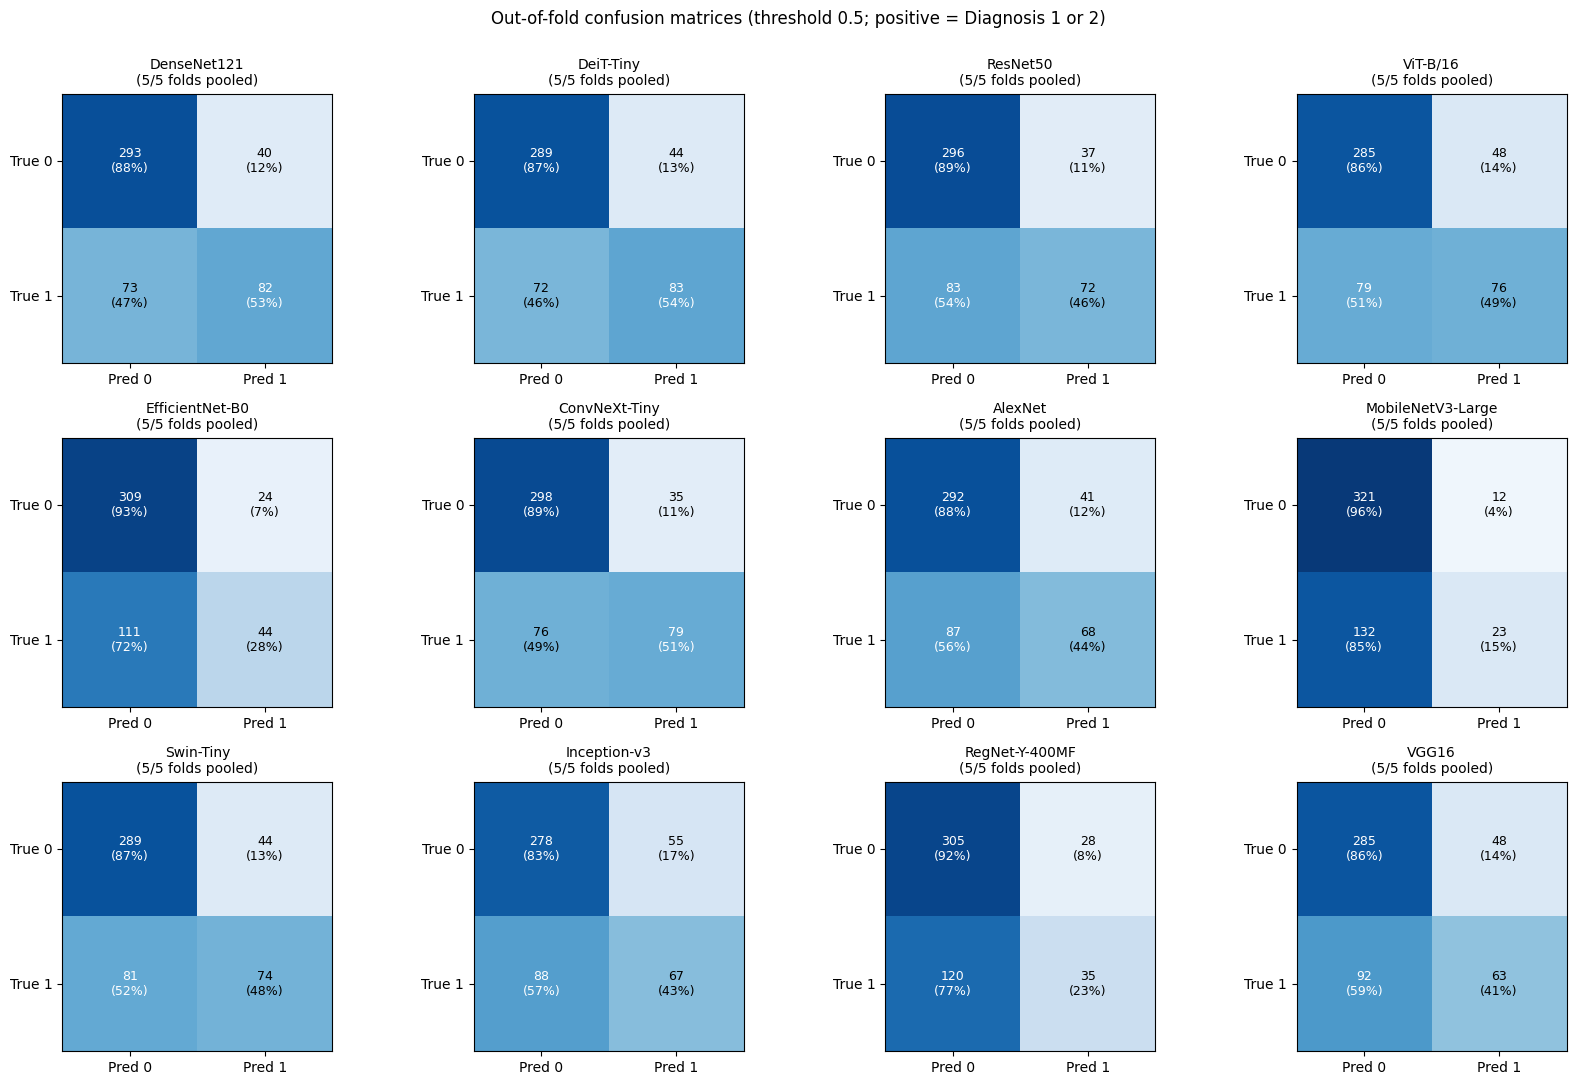

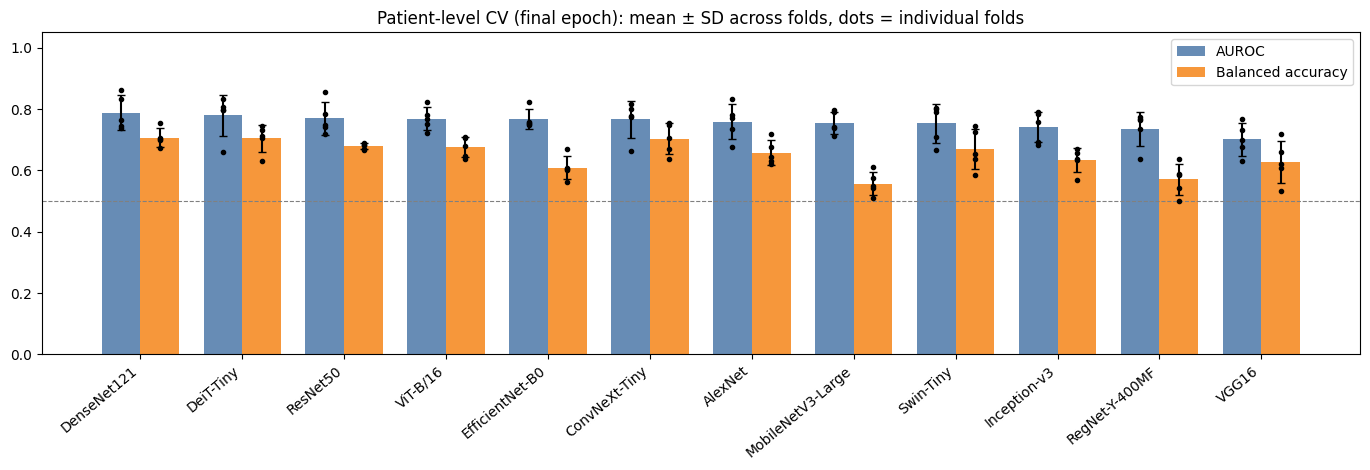

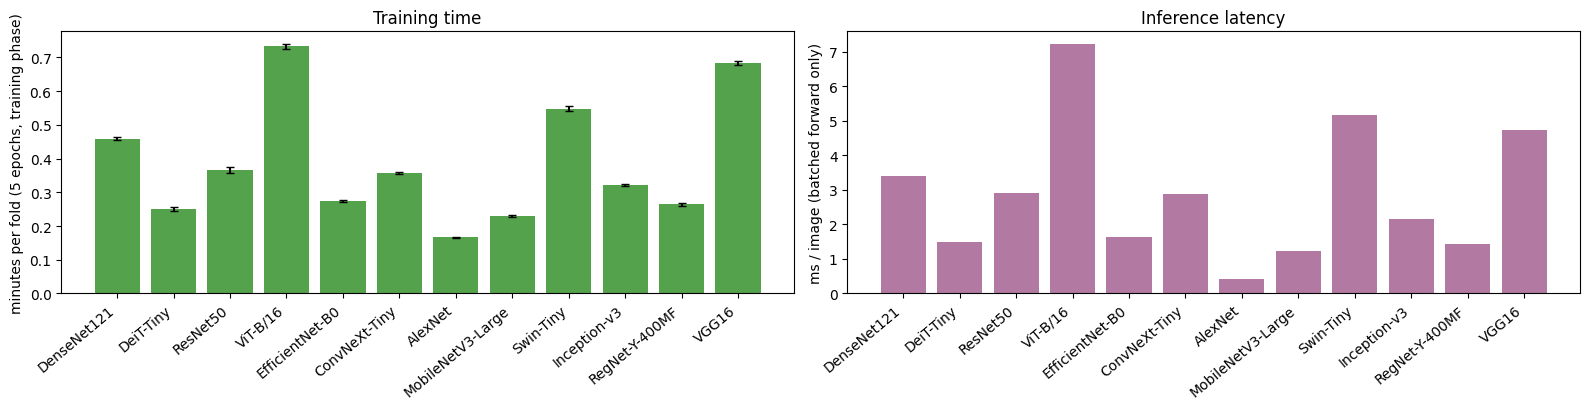

In [17]:
# ---- plots ----
order = [m for m in SUMMARY.sort_values(["rank", "model"], na_position="last").model if SUMMARY.set_index("model").loc[m, "n_folds_complete"] > 0]
S = SUMMARY.set_index("model").loc[order]

# 1) pooled out-of-fold confusion matrices (counts + row-normalised %), [[TN, FP], [FN, TP]]
ncol = 4; nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.6 * nrow)); axes = np.atleast_1d(axes).ravel()
for ax, name in zip(axes, order):
    r = S.loc[name]; cm = np.array([[r.oof_tn, r.oof_fp], [r.oof_fn, r.oof_tp]], dtype=float)
    pct = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(pct, vmin=0, vmax=1, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, f"{int(cm[i, j])}\n({pct[i, j]*100:.0f}%)", ha="center", va="center", color="white" if pct[i, j] > .5 else "black", fontsize=9)
    ax.set_xticks([0, 1], ["Pred 0", "Pred 1"]); ax.set_yticks([0, 1], ["True 0", "True 1"])
    ax.set_title(f"{name}\n({int(r.n_folds_complete)}/{int(r.n_folds_expected)} folds pooled)", fontsize=10)
for ax in axes[len(order):]: ax.axis("off")
plt.suptitle("Out-of-fold confusion matrices (threshold 0.5; positive = Diagnosis 1 or 2)", y=1.0); plt.tight_layout(); plt.savefig(WORK / "confusion_matrices.png", dpi=130, bbox_inches="tight"); plt.show()

# 2) balanced accuracy and AUROC (mean ± SD across folds) - individual fold points overlaid
fig, ax = plt.subplots(figsize=(max(9, 0.9 * len(order) + 3), 4.8)); x = np.arange(len(order)); w = 0.38
for off, key, lab, col in ((-w / 2, "auroc", "AUROC", "#4C78A8"), (w / 2, "balanced_accuracy", "Balanced accuracy", "#F58518")):
    ax.bar(x + off, S[f"{key}_mean"].fillna(0), w, yerr=S[f"{key}_std"].fillna(0), capsize=3, label=lab, color=col, alpha=.85)
    for i, m in enumerate(order):
        v = FOLD_METRICS.loc[FOLD_METRICS.model == m, key].dropna(); ax.scatter(np.full(len(v), x[i] + off), v, s=9, color="k", zorder=3)
ax.set_xticks(x, order, rotation=40, ha="right"); ax.set_ylim(0, 1.05); ax.axhline(0.5, ls="--", c="grey", lw=.8)
ax.set_title("Patient-level CV (final epoch): mean ± SD across folds, dots = individual folds"); ax.legend(); plt.tight_layout(); plt.savefig(WORK / "comparison_balanced_accuracy_auroc.png", dpi=130); plt.show()

# 3) runtime comparison
fig, ax = plt.subplots(1, 2, figsize=(max(10, 1.0 * len(order) + 4), 4.2))
ax[0].bar(order, S["train_time_s_mean"] / 60, yerr=S["train_time_s_std"].fillna(0) / 60, capsize=3, color="#54A24B"); ax[0].set_ylabel("minutes per fold (5 epochs, training phase)"); ax[0].set_title("Training time")
ax[1].bar(order, S["latency_ms_per_image_mean"], color="#B279A2"); ax[1].set_ylabel("ms / image (batched forward only)"); ax[1].set_title("Inference latency")
for a in ax: a.set_xticks(range(len(order)), order, rotation=40, ha="right")
plt.tight_layout(); plt.savefig(WORK / "runtime_comparison.png", dpi=130); plt.show()

## 17. Checkpoint verification and resume instructions

Every completed run is checked (files present, signature and checkpoint metadata compatible, total disk usage). One checkpoint is additionally **re-loaded and re-evaluated** to confirm that it reproduces the stored predictions (small differences are expected because weights are stored in fp16).

**Disk trade-off:** weights only (no optimizer state — runs are atomic, resume works at run granularity), stored in fp16 (~½ size). `final.pt` (the model behind the reported metrics) plus the diagnostic `best_val_auroc.pt` per run is the dominant output size (VGG16/AlexNet/ViT largest). Set `CFG["save_best_val_ckpt"]=False` to halve it, or `CFG["ckpt_dtype"]="float32"` for full precision.

**Resume instructions**
1. *Same session / re-run:* simply re-run the notebook from the top. Completed runs whose signature matches (config + split + validation patients + checkpoint metadata) are skipped; failed or incomplete ones are retried. Any mismatch is printed (`resume_rejected`) and that run is retrained.
2. *New session:* save the notebook output as a Kaggle dataset, attach it, and set `CFG["resume_source"] = "/kaggle/input/<your-output-dataset>"` in Section 9 — completed run folders are copied into `/kaggle/working/runs` before training.
3. Change any setting in `SIG_KEYS` (e.g. epochs, lr) and all runs become incompatible and will be retrained.

In [18]:
assert AUDIT_PASSED
rows, total_bytes = [], 0
for name in MODELS:
    for fold in range(CFG["n_folds"]):
        rd = run_dir(name, fold)
        if not rd.exists(): continue
        ok, why = check_resume(name, fold)
        size = sum(f.stat().st_size for f in rd.rglob("*") if f.is_file()); total_bytes += size
        rows.append(dict(model=name, fold=fold, valid=ok, problems=why, size_mb=round(size / 1024**2, 1)))
CK = pd.DataFrame(rows); display(CK.groupby("model").agg(runs=("fold", "count"), valid=("valid", "sum"), size_mb=("size_mb", "sum")))
print(f"Total size of runs/: {total_bytes / 1024**3:.2f} GiB | free disk now: {shutil.disk_usage(WORK).free / 1024**3:.1f} GiB")
if not CK["valid"].all(): print("WARNING - runs failing validation:"); display(CK[~CK["valid"]])

# round-trip verification of ONE checkpoint: reload final.pt -> re-evaluate -> compare with stored predictions
cand_runs = FOLD_METRICS.sort_values("params_total").iloc[0]
vn, vf = cand_runs["model"], int(cand_runs["fold"])
model, _ = build_model(vn)
ck = torch.load(run_dir(vn, vf) / "final.pt", map_location="cpu", weights_only=True)
model.load_state_dict({k: (v.float() if v.is_floating_point() else v) for k, v in ck["state_dict"].items()}); model = model.to(DEVICE)
ev = evaluate(model, make_loader(FOLD_IDX[vf][1], False, CFG["eval_batch_size"], MODEL_INFO[vn]["mean"], MODEL_INFO[vn]["std"]))
stored = pd.read_csv(run_dir(vn, vf) / "val_predictions.csv").set_index("filename")["prob_positive"]
re_prob = pd.Series(ev["prob"], index=META.loc[ev["idx"], "filename"].values)
diff = (re_prob - stored.reindex(re_prob.index)).abs()
print(f"Checkpoint round-trip [{vn}, fold {vf}]: max |p_reloaded - p_stored| = {diff.max():.4f}, mean = {diff.mean():.5f}  (fp16 weights -> small differences expected)")
print("Reloaded AUROC:", round(compute_metrics(ev["y_true"], ev["prob"])["auroc"], 4), "| stored AUROC:", round(float(cand_runs["auroc"]), 4))
del model, ck; free_memory()

,runs,valid,size_mb
model,,,
AlexNet,5,5,1087.5
ConvNeXt-Tiny,5,5,531.0
DeiT-Tiny,5,5,106.5
DenseNet121,5,5,136.5
EfficientNet-B0,5,5,78.5
Inception-v3,5,5,418.0
MobileNetV3-Large,5,5,81.5
RegNet-Y-400MF,5,5,76.0
ResNet50,5,5,450.5


Total size of runs/: 7.51 GiB | free disk now: 12.0 GiB
Checkpoint round-trip [RegNet-Y-400MF, fold 1]: max |p_reloaded - p_stored| = 0.0113, mean = 0.00220  (fp16 weights -> small differences expected)
Reloaded AUROC: 0.7734 | stored AUROC: 0.773


## 18. Final artifact inventory and concise conclusions

In [19]:
required = ["metadata_validated.csv", "data_audit_report.json", "training_history.csv", "fold_metrics.csv", "model_summary.csv", "validation_predictions.csv",
            "confusion_matrices.png", "comparison_balanced_accuracy_auroc.png", "runtime_comparison.png", "leaderboard.md", "failed_or_incomplete_runs.csv"]
inv = [dict(file=f, exists=(WORK / f).exists(), size_kb=round((WORK / f).stat().st_size / 1024, 1) if (WORK / f).exists() else None) for f in required]
inv += [dict(file="runs/ (checkpoints, per-run history/predictions)", exists=RUNS_DIR.exists(), size_kb=round(sum(f.stat().st_size for f in RUNS_DIR.rglob('*') if f.is_file()) / 1024, 1))]
display(pd.DataFrame(inv)); assert all(r["exists"] for r in inv), "some required artifacts are missing"

top = SUMMARY[SUMMARY["rank"].notna()].head(3)
print("\nCONCLUSIONS (exploratory; cross-validation estimates only)")
if len(top):
    for r in top.itertuples():
        print(f"  #{int(r.rank)} {r.model}: AUROC {pm_(r.auroc_mean, r.auroc_std)}, balanced accuracy {pm_(r.balanced_accuracy_mean, r.balanced_accuracy_std)}")
    if len(top) > 1 and (top.iloc[0].auroc_mean - top.iloc[1].auroc_mean) < max(top.iloc[0].auroc_std, top.iloc[1].auroc_std):
        print("  Note: the gap between the top two models is smaller than the fold-to-fold SD - not distinguishable with this experiment.")
else:
    print("  No model completed all requested folds - see failed_or_incomplete_runs.csv.")
print("""
Limitations: small dataset; 5 epochs and identical untuned hyper-parameters; standardised 299x299 input (not each model's native size);
final-epoch reporting (no checkpoint selection on held-out folds); positive class merges diagnosis codes 1 and 2; patients' two eyes are correlated;
no external test set; NOT clinically validated. Documented model-specific adaptations: DeiT-Tiny via timm, ViT-B/16 positional-embedding interpolation,
Inception-v3 auxiliary head disabled.""")

,file,exists,size_kb
0,metadata_validated.csv,True,81.3
1,data_audit_report.json,True,19.8
2,training_history.csv,True,70.1
3,fold_metrics.csv,True,16.3
4,model_summary.csv,True,5.4
5,validation_predictions.csv,True,288.3
6,confusion_matrices.png,True,166.3
7,comparison_balanced_accuracy_auroc.png,True,88.7
8,runtime_comparison.png,True,80.0
9,leaderboard.md,True,1.8



CONCLUSIONS (exploratory; cross-validation estimates only)
  #1 DenseNet121: AUROC 0.788 ± 0.056, balanced accuracy 0.706 ± 0.031
  #2 DeiT-Tiny: AUROC 0.779 ± 0.068, balanced accuracy 0.705 ± 0.044
  #3 ResNet50: AUROC 0.769 ± 0.054, balanced accuracy 0.678 ± 0.009
  Note: the gap between the top two models is smaller than the fold-to-fold SD - not distinguishable with this experiment.

Limitations: small dataset; 5 epochs and identical untuned hyper-parameters; standardised 299x299 input (not each model's native size);
final-epoch reporting (no checkpoint selection on held-out folds); positive class merges diagnosis codes 1 and 2; patients' two eyes are correlated;
no external test set; NOT clinically validated. Documented model-specific adaptations: DeiT-Tiny via timm, ViT-B/16 positional-embedding interpolation,
Inception-v3 auxiliary head disabled.
